# ResNet-50 U-Net flood segmentation

In [ ]:
from google.colab import drive
from pathlib import Path
import torch
import torchvision

drive.mount("/content/drive")

ZIP_PATH = Path("/content/drive/MyDrive/DLP_Project/flood_area.zip")
OUTPUT_DIR = Path("/content/drive/MyDrive/DLP_Project/resnet50_centralized")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    memory_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"GPU memory: {memory_gb:.1f} GB")

print("Dataset ZIP found:", ZIP_PATH.is_file())

if ZIP_PATH.is_file():
    print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024 ** 2):.1f} MB")

assert torch.cuda.is_available(), (
    "Enable a GPU under Runtime → Change runtime type, then rerun this cell."
)
assert ZIP_PATH.is_file(), (
    f"Upload the dataset ZIP to this exact location: {ZIP_PATH}"
)

print("\nSetup passed. Ready to inspect the dataset.")

Mounted at /content/drive
Mounted at /content/drive
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
GPU available: True
GPU: Tesla T4
GPU memory: 14.6 GB
Dataset ZIP found: True
ZIP size: 106.9 MB

Setup passed. Ready to inspect the dataset.
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
GPU available: True
GPU: Tesla T4
GPU memory: 14.6 GB
Dataset ZIP found: True
ZIP size: 106.9 MB

Setup passed. Ready to inspect the dataset.


## Dataset inspection and mask corrections

In [ ]:
import zipfile
import pandas as pd
from pathlib import PurePosixPath

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    entries = [
        entry for entry in archive.infolist()
        if not entry.is_dir()
        and "__MACOSX" not in entry.filename
        and not PurePosixPath(entry.filename).name.startswith(".")
    ]

    bad_file = archive.testzip()
    assert bad_file is None, f"Corrupted ZIP entry: {bad_file}"

    image_files = [
        entry.filename for entry in entries
        if PurePosixPath(entry.filename).suffix.lower()
        in {".jpg", ".jpeg", ".png"}
    ]

    metadata_files = [
        entry.filename for entry in entries
        if PurePosixPath(entry.filename).name.lower() == "metadata.csv"
    ]

    print("ZIP integrity: passed")
    print("Total files:", len(entries))
    print("Image files, including masks:", len(image_files))

    print("\nFirst 12 file paths:")
    for entry in entries[:12]:
        print(" ", entry.filename)

    print("\nMetadata files:", metadata_files)

    assert len(metadata_files) == 1, (
        "Expected one metadata.csv. Share this output before continuing."
    )

    METADATA_ZIP_PATH = metadata_files[0]

    with archive.open(METADATA_ZIP_PATH) as metadata_file:
        metadata_preview = pd.read_csv(metadata_file)

    print("\nMetadata shape:", metadata_preview.shape)
    print("Column names:", metadata_preview.columns.tolist())
    print("\nFirst five rows:")
    display(metadata_preview.head())

    print("\nMissing values per column:")
    print(metadata_preview.isna().sum())

ZIP integrity: passed
Total files: 581
Image files, including masks: 580

First 12 file paths:
  Image/0.jpg
  Image/1.jpg
  Image/10.jpg
  Image/1000.jpg
  Image/1001.jpg
  Image/1002.jpg
  Image/1003.jpg
  Image/1004.jpg
  Image/1005.jpg
  Image/1006.jpg
  Image/1007.jpg
  Image/1008.jpg

Metadata files: ['metadata.csv']

Metadata shape: (290, 2)
Column names: ['Image', 'Mask']

First five rows:


,Image,Mask
0,0.jpg,0.png
1,1.jpg,1.png
2,2.jpg,2.png
3,3.jpg,3.png
4,4.jpg,4.png



Missing values per column:
Image    0
Mask     0
dtype: int64


## Extract dataset

In [ ]:
import numpy as np
from PIL import Image

extract_dir = Path("/content/dlp_flood_data")
with zipfile.ZipFile(ZIP_PATH) as archive:
    archive.extractall(extract_dir, members=image_files + [METADATA_ZIP_PATH])
DATA_ROOT = (extract_dir / METADATA_ZIP_PATH).parent
metadata = pd.read_csv(DATA_ROOT / "metadata.csv")
print("Loaded image-mask pairs:", len(metadata))


### Dataset extraction

14.jpg: mask range 0–255, intermediate-value pixels 1.66%
15.jpg: mask range 0–255, intermediate-value pixels 1.06%
2052.jpg: mask range 0–255, intermediate-value pixels 0.55%
2053.jpg: mask range 0–255, intermediate-value pixels 1.09%
3059.jpg: mask range 0–255, intermediate-value pixels 0.72%
1061.jpg: mask range 0–255, intermediate-value pixels 0.94%
1079.jpg: mask range 0–255, intermediate-value pixels 0.72%


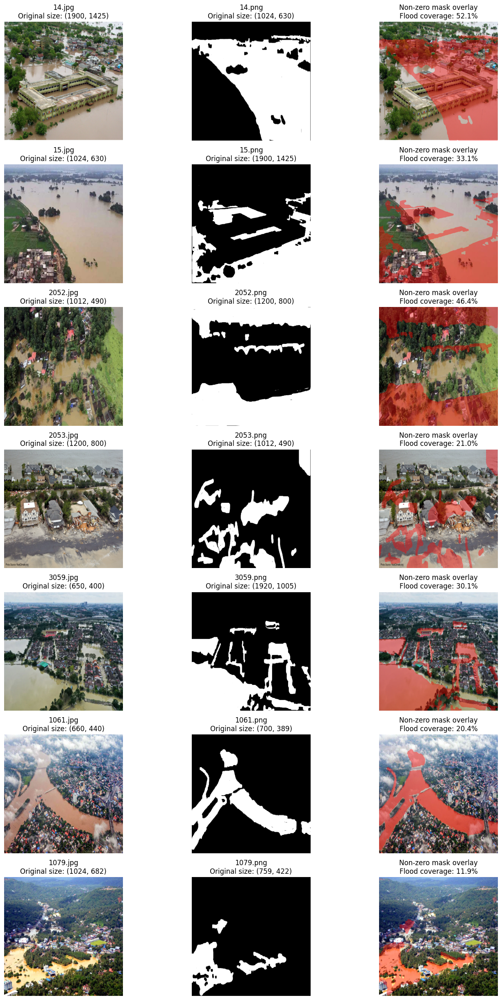

In [ ]:
import matplotlib.pyplot as plt

suspect_images = [
    "14.jpg", "15.jpg",
    "2052.jpg", "2053.jpg",
    "3059.jpg", "1061.jpg", "1079.jpg"
]

fig, axes = plt.subplots(
    len(suspect_images), 3,
    figsize=(15, 3.5 * len(suspect_images))
)

for i, filename in enumerate(suspect_images):
    row = metadata.loc[metadata["Image"] == filename].iloc[0]

    with Image.open(DATA_ROOT / "Image" / row["Image"]) as image:
        image_rgb = image.convert("RGB")
        original_image_size = image.size
        image_display = np.array(
            image_rgb.resize((512, 512), Image.Resampling.BILINEAR)
        )

    with Image.open(DATA_ROOT / "Mask" / row["Mask"]) as mask:
        original_mask_size = mask.size
        mask_gray = mask.convert("L")
        raw_mask = np.array(mask_gray)
        resized_mask = np.array(
            mask_gray.resize((512, 512), Image.Resampling.NEAREST)
        )

    binary_mask = resized_mask > 0

    overlay = image_display.astype(np.float32) / 255.0
    overlay[binary_mask] = (
        0.6 * overlay[binary_mask]
        + 0.4 * np.array([1.0, 0.0, 0.0])
    )

    axes[i, 0].imshow(image_display)
    axes[i, 0].set_title(
        f'{filename}\nOriginal size: {original_image_size}'
    )

    axes[i, 1].imshow(resized_mask, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title(
        f'{row["Mask"]}\nOriginal size: {original_mask_size}'
    )

    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title(
        f"Non-zero mask overlay\n"
        f"Flood coverage: {binary_mask.mean():.1%}"
    )

    for ax in axes[i]:
        ax.axis("off")

    intermediate = ((raw_mask > 0) & (raw_mask < 255)).mean()
    print(
        f"{filename}: "
        f"mask range {raw_mask.min()}–{raw_mask.max()}, "
        f"intermediate-value pixels {intermediate:.2%}"
    )

plt.tight_layout()
plt.show()

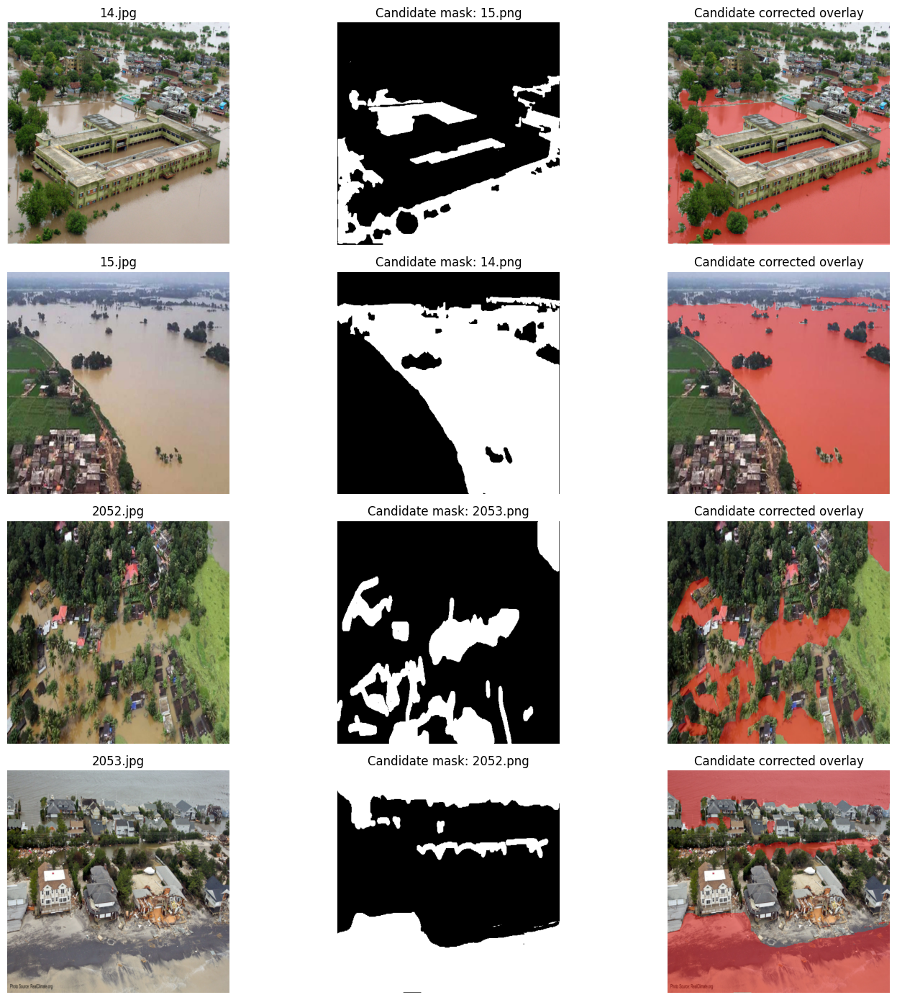

In [ ]:
candidate_pairs = [
    ("14.jpg", "15.png"),
    ("15.jpg", "14.png"),
    ("2052.jpg", "2053.png"),
    ("2053.jpg", "2052.png"),
]

fig, axes = plt.subplots(4, 3, figsize=(15, 14))

for i, (image_name, mask_name) in enumerate(candidate_pairs):
    with Image.open(DATA_ROOT / "Image" / image_name) as image:
        image_array = np.array(
            image.convert("RGB").resize(
                (512, 512), Image.Resampling.BILINEAR
            )
        )

    with Image.open(DATA_ROOT / "Mask" / mask_name) as mask:
        mask_array = np.array(
            mask.convert("L").resize(
                (512, 512), Image.Resampling.NEAREST
            )
        )

    binary_mask = mask_array > 0

    overlay = image_array.astype(np.float32) / 255.0
    overlay[binary_mask] = (
        0.6 * overlay[binary_mask]
        + 0.4 * np.array([1.0, 0.0, 0.0])
    )

    axes[i, 0].imshow(image_array)
    axes[i, 0].set_title(image_name)

    axes[i, 1].imshow(binary_mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title(f"Candidate mask: {mask_name}")

    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title("Candidate corrected overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
corrections = {
    "14.jpg": "15.png",
    "15.jpg": "14.png",
    "2052.jpg": "2053.png",
    "2053.jpg": "2052.png",
}


metadata_corrected = pd.read_csv(DATA_ROOT / "metadata.csv")

correction_log = []

for image_name, corrected_mask in corrections.items():
    selection = metadata_corrected["Image"] == image_name
    assert selection.sum() == 1, f"Expected one row for {image_name}"

    original_mask = metadata_corrected.loc[selection, "Mask"].iloc[0]

    correction_log.append({
        "Image": image_name,
        "Original_Mask": original_mask,
        "Corrected_Mask": corrected_mask,
        "Reason": "Swapped pairing confirmed by visual inspection",
    })

    metadata_corrected.loc[selection, "Mask"] = corrected_mask

assert len(metadata_corrected) == 290
assert metadata_corrected["Image"].is_unique
assert metadata_corrected["Mask"].is_unique

remaining_size_mismatches = []

for row in metadata_corrected.itertuples(index=False):
    with Image.open(DATA_ROOT / "Image" / row.Image) as image:
        image_size = image.size

    with Image.open(DATA_ROOT / "Mask" / row.Mask) as mask:
        mask_size = mask.size

    if image_size != mask_size:
        remaining_size_mismatches.append(row.Image)

assert set(remaining_size_mismatches) == {
    "3059.jpg", "1061.jpg", "1079.jpg"
}, f"Unexpected dimension mismatches: {remaining_size_mismatches}"


DATA_RECORD_DIR = ZIP_PATH.parent / "dataset_records"
DATA_RECORD_DIR.mkdir(parents=True, exist_ok=True)

metadata_corrected.to_csv(
    DATA_RECORD_DIR / "metadata_corrected.csv", index=False
)

correction_log = pd.DataFrame(correction_log)
correction_log.to_csv(
    DATA_RECORD_DIR / "mask_pairing_corrections.csv", index=False
)

print("Corrected mappings:")
display(correction_log)

print("Total pairs retained:", len(metadata_corrected))
print("Remaining resolution differences:", remaining_size_mismatches)
print("Saved records to:", DATA_RECORD_DIR)
print("\nCorrections recorded. Original dataset files unchanged.")

Corrected mappings:


,Image,Original_Mask,Corrected_Mask,Reason
0,14.jpg,14.png,15.png,Swapped pairing confirmed by visual inspection
1,15.jpg,15.png,14.png,Swapped pairing confirmed by visual inspection
2,2052.jpg,2052.png,2053.png,Swapped pairing confirmed by visual inspection
3,2053.jpg,2053.png,2052.png,Swapped pairing confirmed by visual inspection


Total pairs retained: 290
Remaining resolution differences: ['3059.jpg', '1061.jpg', '1079.jpg']
Saved records to: /content/drive/MyDrive/DLP_Project/dataset_records

Corrections recorded. Original dataset files unchanged.


In [ ]:
SEED = 42

total_size = len(metadata_corrected)
train_size = int(0.75 * total_size)
val_size = int(0.10 * total_size)
test_size = total_size - train_size - val_size

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(total_size, generator=generator).tolist()

train_indices = indices[:train_size]
test_indices = indices[train_size:train_size + test_size]
val_indices = indices[train_size + test_size:]

train_df = metadata_corrected.iloc[train_indices].reset_index(drop=True)
val_df = metadata_corrected.iloc[val_indices].reset_index(drop=True)
test_df = metadata_corrected.iloc[test_indices].reset_index(drop=True)

train_names = set(train_df["Image"])
val_names = set(val_df["Image"])
test_names = set(test_df["Image"])

assert train_names.isdisjoint(val_names)
assert train_names.isdisjoint(test_names)
assert val_names.isdisjoint(test_names)
assert len(train_names | val_names | test_names) == total_size

split_frames = {
    "train": train_df,
    "val": val_df,
    "test": test_df,
}


for split_name, frame in split_frames.items():
    path = DATA_RECORD_DIR / f"{split_name}_seed{SEED}.csv"

    if path.exists():
        existing = pd.read_csv(path)
        assert existing.equals(frame), (
            f"{path.name} already contains a different split. "
            "Stop and share this error."
        )

for split_name, frame in split_frames.items():
    path = DATA_RECORD_DIR / f"{split_name}_seed{SEED}.csv"
    if not path.exists():
        frame.to_csv(path, index=False)

    print(f"{split_name}: {len(frame)} images")

print("\nFirst five training pairs:")
display(train_df.head())

print("Overlap check: passed")
print("Split records:", DATA_RECORD_DIR)

train: 217 images
val: 29 images
test: 44 images

First five training pairs:


,Image,Mask
0,2.jpg,2.png
1,3031.jpg,3031.png
2,3023.jpg,3023.png
3,1.jpg,1.png
4,3035.jpg,3035.png


Overlap check: passed
Split records: /content/drive/MyDrive/DLP_Project/dataset_records


## Dataset loaders

Image batch: torch.Size([8, 3, 512, 512]) torch.float32
Mask batch: torch.Size([8, 1, 512, 512]) torch.float32
Mask values: [0.0, 1.0]
Normalized image range: -2.118 to 2.640
Training batches: 28
Validation batches: 4
Test batches: 6


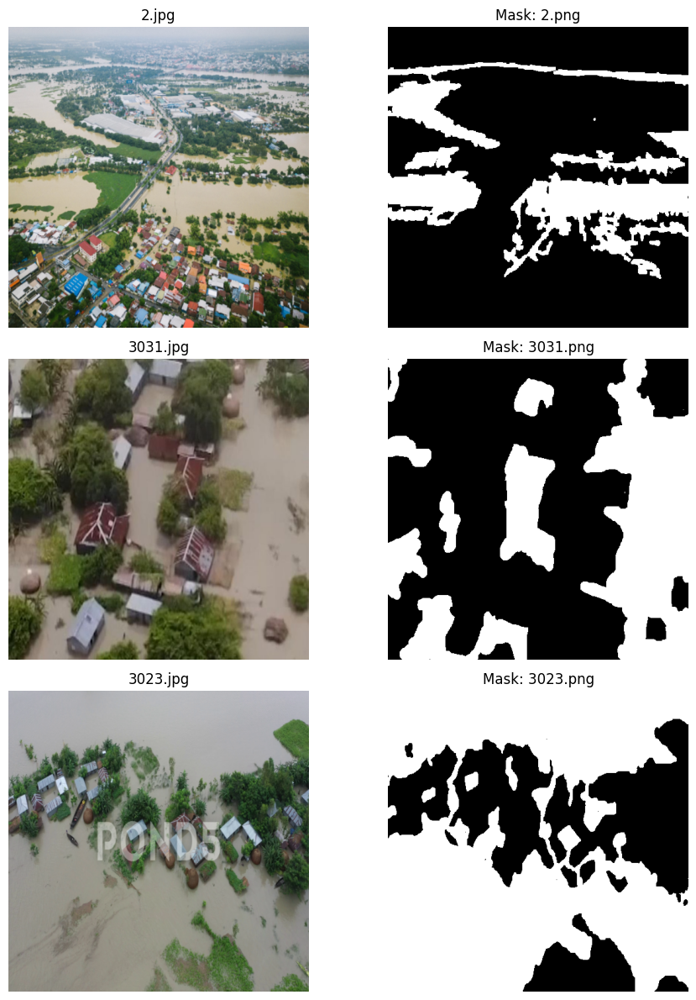


Dataset loader checks passed.


In [ ]:
from torch.utils.data import Dataset, DataLoader

IMAGE_SIZE = (512, 512)
BATCH_SIZE = 8

IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406], dtype=torch.float32
).view(3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225], dtype=torch.float32
).view(3, 1, 1)


class FloodDataset(Dataset):
    def __init__(self, dataframe, data_root):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.data_root = Path(data_root)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(self.data_root / "Image" / row["Image"]) as image:
            image = image.convert("RGB").resize(
                IMAGE_SIZE, Image.Resampling.BILINEAR
            )
            image = np.array(image, dtype=np.float32) / 255.0

        with Image.open(self.data_root / "Mask" / row["Mask"]) as mask:
            mask = mask.convert("L").resize(
                IMAGE_SIZE, Image.Resampling.NEAREST
            )
            mask = (np.array(mask) > 0).astype(np.float32)

        image = torch.from_numpy(image).permute(2, 0, 1).contiguous()
        image = (image - IMAGENET_MEAN) / IMAGENET_STD
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


train_dataset = FloodDataset(train_df, DATA_ROOT)
val_dataset = FloodDataset(val_df, DATA_ROOT)
test_dataset = FloodDataset(test_df, DATA_ROOT)

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    generator=loader_generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

check_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
images, masks = next(iter(check_loader))

assert images.shape == (BATCH_SIZE, 3, 512, 512)
assert masks.shape == (BATCH_SIZE, 1, 512, 512)
assert images.dtype == masks.dtype == torch.float32
assert torch.isfinite(images).all()
assert torch.isfinite(masks).all()
assert ((masks == 0) | (masks == 1)).all()

print("Image batch:", images.shape, images.dtype)
print("Mask batch:", masks.shape, masks.dtype)
print("Mask values:", torch.unique(masks).tolist())
print(f"Normalized image range: {images.min():.3f} to {images.max():.3f}")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

display_images = (
    images * IMAGENET_STD + IMAGENET_MEAN
).clamp(0, 1)

fig, axes = plt.subplots(3, 2, figsize=(10, 12))

for i in range(3):
    axes[i, 0].imshow(display_images[i].permute(1, 2, 0).numpy())
    axes[i, 0].set_title(train_df.iloc[i]["Image"])

    axes[i, 1].imshow(masks[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title(f'Mask: {train_df.iloc[i]["Mask"]}')

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("\nDataset loader checks passed.")

## Centralized ResNet-50 U-Net

In [ ]:
import random
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50, ResNet50_Weights

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda")


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.conv = DoubleConv(in_channels + skip_channels, out_channels)

    def forward(self, x, skip):
        x = F.interpolate(
            x, size=skip.shape[-2:],
            mode="bilinear", align_corners=False
        )
        return self.conv(torch.cat([x, skip], dim=1))


class ResNet50UNet(nn.Module):
    def __init__(self):
        super().__init__()

        encoder = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)

        self.stem = nn.Sequential(
            encoder.conv1, encoder.bn1, encoder.relu
        )
        self.pool = encoder.maxpool
        self.encoder1 = encoder.layer1
        self.encoder2 = encoder.layer2
        self.encoder3 = encoder.layer3
        self.encoder4 = encoder.layer4

        self.decoder4 = DecoderBlock(2048, 1024, 256)
        self.decoder3 = DecoderBlock(256, 512, 128)
        self.decoder2 = DecoderBlock(128, 256, 64)
        self.decoder1 = DecoderBlock(64, 64, 32)

        self.final_decoder = DoubleConv(32, 16)
        self.head = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        input_size = x.shape[-2:]

        s0 = self.stem(x)
        s1 = self.encoder1(self.pool(s0))
        s2 = self.encoder2(s1)
        s3 = self.encoder3(s2)
        bottleneck = self.encoder4(s3)

        x = self.decoder4(bottleneck, s3)
        x = self.decoder3(x, s2)
        x = self.decoder2(x, s1)
        x = self.decoder1(x, s0)

        x = F.interpolate(
            x, size=input_size,
            mode="bilinear", align_corners=False
        )
        return self.head(self.final_decoder(x))


model = ResNet50UNet().to(device)

model.eval()

with torch.inference_mode():
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        check_logits = model(images[:2].to(device))

assert check_logits.shape == (2, 1, 512, 512)
assert torch.isfinite(check_logits).all()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Device:", device)
print("Output shape:", check_logits.shape)
print("Output values finite:", torch.isfinite(check_logits).all().item())
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("Encoder weights: ImageNet ResNet50 V1")
print("Decoder: randomly initialized")

del check_logits
torch.cuda.empty_cache()

print("\nModel forward check passed.")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 59.7MB/s]


Device: cuda
Output shape: torch.Size([2, 1, 512, 512])
Output values finite: True
Total parameters: 32,520,977
Trainable parameters: 32,520,977
Encoder weights: ImageNet ResNet50 V1
Decoder: randomly initialized

Model forward check passed.


In [ ]:
criterion = nn.BCEWithLogitsLoss()

saved_buffers = {
    name: buffer.detach().clone()
    for name, buffer in model.named_buffers()
}
saved_cpu_rng = torch.get_rng_state()
saved_cuda_rng = torch.cuda.get_rng_state()
previous_mode = model.training

model.zero_grad(set_to_none=True)
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

batch_images = images.to(device, non_blocking=True)
batch_masks = masks.to(device, non_blocking=True)

check_scaler = torch.amp.GradScaler("cuda")

try:
    model.train()

    with torch.autocast(device_type="cuda", dtype=torch.float16):
        logits = model(batch_images)
        loss = criterion(logits, batch_masks)

    assert torch.isfinite(loss).item(), "Loss is not finite."

    check_scaler.scale(loss).backward()

    gradients = [
        parameter.grad
        for parameter in model.parameters()
        if parameter.requires_grad and parameter.grad is not None
    ]

    assert gradients, "No gradients were produced."
    assert all(
        torch.isfinite(gradient).all().item()
        for gradient in gradients
    ), "Non-finite gradients detected."

    assert model.stem[0].weight.grad is not None, (
        "The encoder is not receiving gradients."
    )
    assert model.head.weight.grad is not None, (
        "The segmentation head is not receiving gradients."
    )

    torch.cuda.synchronize()

    print("Batch size:", batch_images.shape[0])
    print("Logits shape:", logits.shape)
    print(f"BCE loss: {loss.item():.6f}")
    print("Encoder gradients: passed")
    print("Decoder/head gradients: passed")
    print("All computed gradients finite: passed")
    print(
        "Peak allocated GPU memory: "
        f"{torch.cuda.max_memory_allocated() / 1024**3:.2f} GB"
    )
    print(
        "Peak reserved GPU memory: "
        f"{torch.cuda.max_memory_reserved() / 1024**3:.2f} GB"
    )

finally:
    model.zero_grad(set_to_none=True)

    with torch.no_grad():
        for name, buffer in model.named_buffers():
            buffer.copy_(saved_buffers[name])

    torch.set_rng_state(saved_cpu_rng)
    torch.cuda.set_rng_state(saved_cuda_rng)
    model.train(previous_mode)

    del saved_buffers, batch_images, batch_masks, check_scaler

    if "gradients" in globals():
        del gradients
    if "logits" in globals():
        del logits
    if "loss" in globals():
        del loss

    torch.cuda.empty_cache()

print("\nBackward check passed. No model weights were updated.")

Batch size: 8
Logits shape: torch.Size([8, 1, 512, 512])
BCE loss: 0.723117
Encoder gradients: passed
Decoder/head gradients: passed
All computed gradients finite: passed
Peak allocated GPU memory: 3.20 GB
Peak reserved GPU memory: 3.39 GB

Backward check passed. No model weights were updated.


In [ ]:
LEARNING_RATE = 0.001
NUM_EPOCHS = 300

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999),
)

scaler = torch.amp.GradScaler("cuda")


def run_epoch(loader, training=False):
    model.train(training)

    total_loss = 0.0
    sample_count = 0

    
    counts = torch.zeros(4, dtype=torch.int64, device=device)

    with torch.set_grad_enabled(training):
        for batch_images, batch_masks in loader:
            batch_images = batch_images.to(device, non_blocking=True)
            batch_masks = batch_masks.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(batch_images)
                loss = criterion(logits, batch_masks)

            if not torch.isfinite(loss).item():
                raise RuntimeError("Non-finite loss encountered.")

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            batch_size = batch_images.shape[0]
            total_loss += loss.item() * batch_size
            sample_count += batch_size

            
            predicted = logits.detach() > 0
            target = batch_masks > 0.5

            counts += torch.stack([
                (predicted & target).sum(),       
                (predicted & ~target).sum(),      
                (~predicted & target).sum(),      
                (~predicted & ~target).sum(),     
            ])

    tp, fp, fn, tn = counts.cpu().tolist()

    
    return {
        "loss": total_loss / sample_count,
        "iou": tp / max(tp + fp + fn, 1),
        "precision": tp / max(tp + fp, 1),
        "recall": tp / max(tp + fn, 1),
        "f1": (2 * tp) / max(2 * tp + fp + fn, 1),
        "pixel_accuracy": (tp + tn) / max(tp + fp + fn + tn, 1),
    }


initial_val_metrics = run_epoch(val_loader, training=False)

print("Initial validation metrics — before training:")
for name, value in initial_val_metrics.items():
    print(f"{name}: {value:.6f}")

print("\nOptimizer:", type(optimizer).__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Maximum epochs:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Loss: BCEWithLogitsLoss")
print("Mixed precision: enabled")
print("\nTraining/evaluation setup passed. No training performed.")

Initial validation metrics — before training:
loss: 0.711549
iou: 0.417038
precision: 0.417038
recall: 1.000000
f1: 0.588605
pixel_accuracy: 0.417038

Optimizer: Adam
Learning rate: 0.001
Maximum epochs: 300
Batch size: 8
Loss: BCEWithLogitsLoss
Mixed precision: enabled

Training/evaluation setup passed. No training performed.


In [ ]:
import os
import time

BEST_PATH = OUTPUT_DIR / "best_checkpoint.pt"
LAST_PATH = OUTPUT_DIR / "last_checkpoint.pt"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"

experiment_config = {
    "model": "ResNet50UNet",
    "encoder_weights": "IMAGENET1K_V1",
    "image_size": list(IMAGE_SIZE),
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "optimizer": "Adam",
    "loss": "BCEWithLogitsLoss",
    "mask_rule": "nonzero_is_flood",
    "seed": SEED,
    "splits": {
        name: frame[["Image", "Mask"]].to_dict("records")
        for name, frame in split_frames.items()
    },
}


def save_checkpoint(path, state):
    temporary_path = path.with_suffix(".tmp")
    torch.save(state, temporary_path)
    os.replace(temporary_path, path)


start_epoch = 0
best_val_iou = -1.0
history = []

if LAST_PATH.exists():
    
    checkpoint = torch.load(
        LAST_PATH, map_location="cpu", weights_only=False
    )

    assert checkpoint["config"] == experiment_config, (
        "Existing checkpoint belongs to a different configuration. "
        "Stop and share this error."
    )

    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])
    scaler.load_state_dict(checkpoint["scaler_state"])

    start_epoch = checkpoint["epoch"]
    best_val_iou = checkpoint["best_val_iou"]
    history = checkpoint["history"]

    random.setstate(checkpoint["python_rng"])
    np.random.set_state(checkpoint["numpy_rng"])
    torch.set_rng_state(checkpoint["torch_rng"])
    torch.cuda.set_rng_state(checkpoint["cuda_rng"])
    loader_generator.set_state(checkpoint["loader_rng"])

    
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    del checkpoint
    print(f"Resuming after epoch {start_epoch}.")
else:
    assert not BEST_PATH.exists() and not HISTORY_PATH.exists(), (
        "Existing results found without a resumable checkpoint. "
        "Stop and share this message before overwriting anything."
    )
    print("Starting a new training run.")

print("Results directory:", OUTPUT_DIR)

for epoch in range(start_epoch, NUM_EPOCHS):
    epoch_start = time.time()

    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    improved = val_metrics["iou"] > best_val_iou
    if improved:
        best_val_iou = val_metrics["iou"]

    row = {
        "epoch": epoch + 1,
        "learning_rate": optimizer.param_groups[0]["lr"],
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "seconds": time.time() - epoch_start,
    }
    history.append(row)

    print(
        f"Epoch {epoch + 1:03d}/{NUM_EPOCHS} | "
        f"Train loss {train_metrics['loss']:.4f} | "
        f"Val loss {val_metrics['loss']:.4f} | "
        f"Val IoU {val_metrics['iou']:.4f} | "
        f"Val F1 {val_metrics['f1']:.4f} | "
        f"{row['seconds']:.1f}s"
        + (" | BEST" if improved else ""),
        flush=True,
    )

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    save_resume = (
        epoch == 0
        or (epoch + 1) % 5 == 0
        or epoch + 1 == NUM_EPOCHS
    )

    if improved or save_resume:
        state = {
            "epoch": epoch + 1,
            "config": experiment_config,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scaler_state": scaler.state_dict(),
            "best_val_iou": best_val_iou,
            "history": history.copy(),
            "python_rng": random.getstate(),
            "numpy_rng": np.random.get_state(),
            "torch_rng": torch.get_rng_state(),
            "cuda_rng": torch.cuda.get_rng_state(),
            "loader_rng": loader_generator.get_state(),
        }

        if improved:
            save_checkpoint(BEST_PATH, state)

        if save_resume:
            save_checkpoint(LAST_PATH, state)

        del state

print(f"\nTraining complete. Best validation IoU: {best_val_iou:.4f}")
print("Best checkpoint:", BEST_PATH)
print("History:", HISTORY_PATH)

Starting a new training run.
Results directory: /content/drive/MyDrive/DLP_Project/resnet50_centralized
Epoch 001/300 | Train loss 0.4846 | Val loss 0.4554 | Val IoU 0.5511 | Val F1 0.7106 | 12.7s | BEST
Epoch 002/300 | Train loss 0.3995 | Val loss 0.3860 | Val IoU 0.7012 | Val F1 0.8243 | 13.4s | BEST
Epoch 003/300 | Train loss 0.3573 | Val loss 0.3022 | Val IoU 0.7673 | Val F1 0.8683 | 13.4s | BEST
Epoch 004/300 | Train loss 0.3357 | Val loss 0.3502 | Val IoU 0.7370 | Val F1 0.8486 | 12.9s
Epoch 005/300 | Train loss 0.3325 | Val loss 0.3193 | Val IoU 0.7496 | Val F1 0.8569 | 14.8s
Epoch 006/300 | Train loss 0.3081 | Val loss 0.2946 | Val IoU 0.7432 | Val F1 0.8527 | 13.3s
Epoch 007/300 | Train loss 0.2789 | Val loss 0.3090 | Val IoU 0.7415 | Val F1 0.8515 | 15.1s
Epoch 008/300 | Train loss 0.2800 | Val loss 0.3593 | Val IoU 0.6540 | Val F1 0.7908 | 13.2s
Epoch 009/300 | Train loss 0.2657 | Val loss 0.3303 | Val IoU 0.7057 | Val F1 0.8274 | 12.9s
Epoch 010/300 | Train loss 0.2586 | Va

KeyboardInterrupt: 

Completed epochs: 91
Best epoch: 26
Best validation IoU: 0.829599
Best validation F1: 0.906864
Validation loss at best IoU: 0.196439


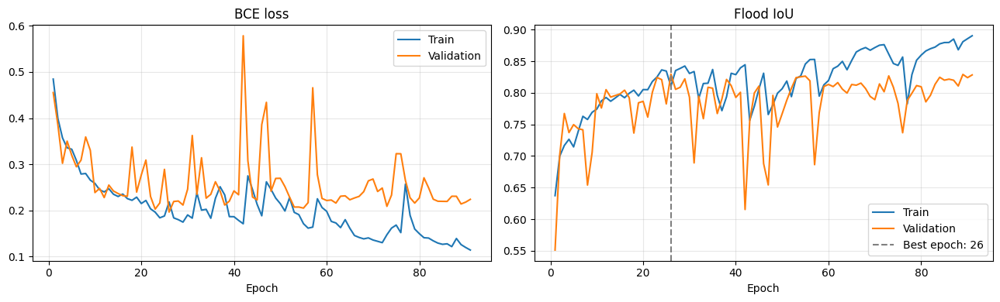

In [ ]:
history_df = pd.read_csv(HISTORY_PATH)

best_row = history_df.loc[history_df["val_iou"].idxmax()]

print("Completed epochs:", int(history_df["epoch"].max()))
print("Best epoch:", int(best_row["epoch"]))
print(f"Best validation IoU: {best_row['val_iou']:.6f}")
print(f"Best validation F1: {best_row['val_f1']:.6f}")
print(f"Validation loss at best IoU: {best_row['val_loss']:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    history_df["epoch"], history_df["train_loss"], label="Train"
)
axes[0].plot(
    history_df["epoch"], history_df["val_loss"], label="Validation"
)
axes[0].set_title("BCE loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history_df["epoch"], history_df["train_iou"], label="Train"
)
axes[1].plot(
    history_df["epoch"], history_df["val_iou"], label="Validation"
)
axes[1].axvline(
    best_row["epoch"], color="gray", linestyle="--",
    label=f"Best epoch: {int(best_row['epoch'])}"
)
axes[1].set_title("Flood IoU")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import json

checkpoint = torch.load(
    BEST_PATH, map_location="cpu", weights_only=False
)

assert checkpoint["config"] == experiment_config, (
    "Checkpoint configuration does not match this experiment."
)

best_epoch = checkpoint["epoch"]
saved_val_iou = checkpoint["best_val_iou"]

model.load_state_dict(checkpoint["model_state"])
model.eval()

del checkpoint

print("Loaded best checkpoint from epoch:", best_epoch)
print(f"Saved validation IoU: {saved_val_iou:.6f}")

verified_val_metrics = run_epoch(val_loader, training=False)

assert abs(verified_val_metrics["iou"] - saved_val_iou) < 1e-4, (
    "Validation score does not match the checkpoint. "
    "Share this error before proceeding."
)

test_metrics = run_epoch(test_loader, training=False)

print("\nHeld-out test results:")
for name, value in test_metrics.items():
    print(f"{name}: {value:.6f}")

results = {
    "experiment": "centralized_supervised_resnet50_unet",
    "checkpoint_epoch": best_epoch,
    "train_images": len(train_dataset),
    "validation_images": len(val_dataset),
    "test_images": len(test_dataset),
    "prediction_threshold": 0.5,
    "metric_aggregation": "pooled_pixel_counts",
    "validation_metrics": verified_val_metrics,
    "test_metrics": test_metrics,
}

RESULTS_PATH = OUTPUT_DIR / "best_model_test_results.json"

with open(RESULTS_PATH, "w") as file:
    json.dump(results, file, indent=2)

print("\nResults saved:", RESULTS_PATH)

Loaded best checkpoint from epoch: 26
Saved validation IoU: 0.829599

Held-out test results:
loss: 0.241252
iou: 0.812619
precision: 0.910837
recall: 0.882848
f1: 0.896624
pixel_accuracy: 0.908975

Results saved: /content/drive/MyDrive/DLP_Project/resnet50_centralized/best_model_test_results.json


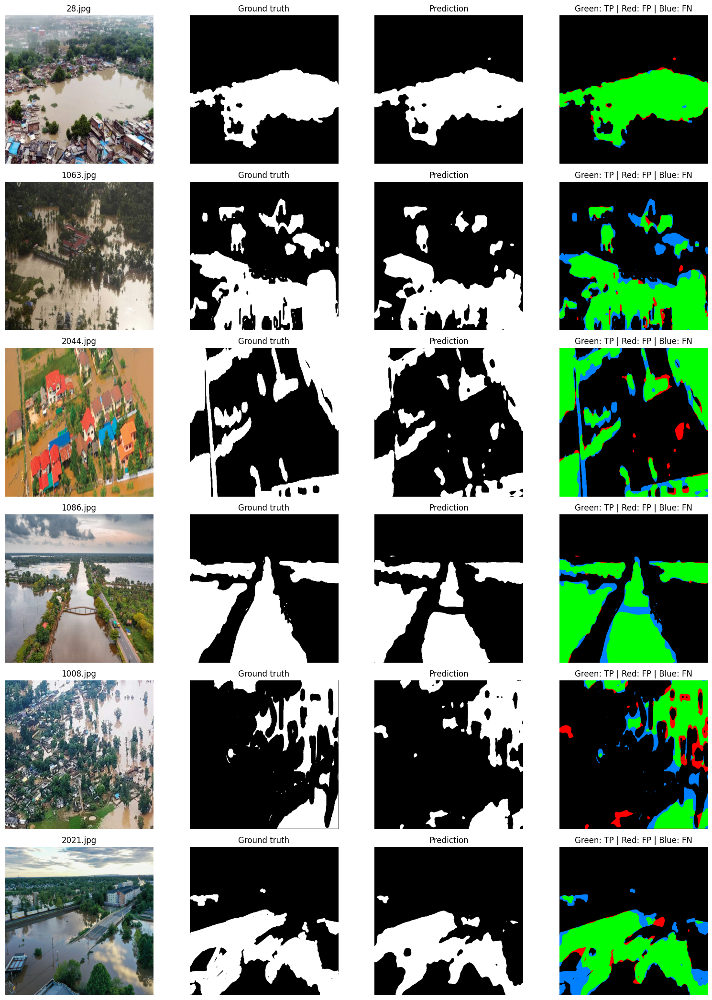

Figure saved: /content/drive/MyDrive/DLP_Project/resnet50_centralized/test_predictions_first6.png


In [ ]:
model.eval()

fig, axes = plt.subplots(6, 4, figsize=(16, 21))

with torch.inference_mode():
    for i in range(6):
        image, mask = test_dataset[i]

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(image.unsqueeze(0).to(device))

        prediction = (logits[0, 0] > 0).cpu().numpy()
        target = mask[0].numpy() > 0.5

        rgb = (
            image * IMAGENET_STD + IMAGENET_MEAN
        ).clamp(0, 1).permute(1, 2, 0).numpy()

        
        
        error_map = np.zeros((*target.shape, 3), dtype=np.float32)
        error_map[prediction & target] = [0, 1, 0]
        error_map[prediction & ~target] = [1, 0, 0]
        error_map[~prediction & target] = [0, 0.5, 1]

        axes[i, 0].imshow(rgb)
        axes[i, 0].set_title(test_df.iloc[i]["Image"])

        axes[i, 1].imshow(target, cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title("Ground truth")

        axes[i, 2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title("Prediction")

        axes[i, 3].imshow(error_map)
        axes[i, 3].set_title("Green: TP | Red: FP | Blue: FN")

        for ax in axes[i]:
            ax.axis("off")

plt.tight_layout()

FIGURE_PATH = OUTPUT_DIR / "test_predictions_first6.png"
fig.savefig(FIGURE_PATH, dpi=150, bbox_inches="tight")

plt.show()
print("Figure saved:", FIGURE_PATH)

## Fully supervised FedAvg

In [ ]:
CLIENT_RECORD_DIR = DATA_RECORD_DIR / "clients_non_iid_seed42"
CLIENT_RECORD_DIR.mkdir(parents=True, exist_ok=True)

partition_df = train_df.copy()
flood_ratios = []

for row in partition_df.itertuples(index=False):
    with Image.open(DATA_ROOT / "Mask" / row.Mask) as mask:
        mask = mask.convert("L").resize(
            IMAGE_SIZE, Image.Resampling.NEAREST
        )
        flood_ratios.append(float((np.array(mask) > 0).mean()))

partition_df["flood_ratio"] = flood_ratios

sorted_indices = np.argsort(
    partition_df["flood_ratio"].to_numpy(),
    kind="stable"
)

client1_indices = sorted_indices[:108]
remaining_indices = sorted_indices[108:]

partition_rng = np.random.default_rng(SEED)
remaining_indices = partition_rng.permutation(remaining_indices)

client_indices = {
    1: client1_indices,
    2: remaining_indices[:51],
    3: remaining_indices[51:],
}

client_dfs = {
    client_id: partition_df.iloc[indices].reset_index(drop=True)
    for client_id, indices in client_indices.items()
}

all_client_images = [
    image_name
    for frame in client_dfs.values()
    for image_name in frame["Image"]
]

assert [len(client_dfs[k]) for k in (1, 2, 3)] == [108, 51, 58]
assert len(all_client_images) == len(set(all_client_images)) == 217
assert set(all_client_images) == set(train_df["Image"])
assert set(all_client_images).isdisjoint(val_df["Image"])
assert set(all_client_images).isdisjoint(test_df["Image"])

for client_id, frame in client_dfs.items():
    path = CLIENT_RECORD_DIR / f"client_{client_id}.csv"
    if path.exists():
        existing = pd.read_csv(path)
        pd.testing.assert_frame_equal(
            existing, frame,
            check_exact=False, rtol=1e-12, atol=1e-12
        )

for client_id, frame in client_dfs.items():
    path = CLIENT_RECORD_DIR / f"client_{client_id}.csv"
    if not path.exists():
        frame.to_csv(path, index=False)

summary_rows = []

for client_id, frame in client_dfs.items():
    summary_rows.append({
        "Client": client_id,
        "Training images": len(frame),
        "Mean flood coverage (%)": round(
            100 * frame["flood_ratio"].mean(), 2
        ),
        "FedAvg weight": round(len(frame) / len(train_df), 6),
    })

client_summary = pd.DataFrame(summary_rows)

display(client_summary)
print("Partition checks: passed")
print("Validation/test images included in clients: none")
print("Saved client records:", CLIENT_RECORD_DIR)

,Client,Training images,Mean flood coverage (%),FedAvg weight
0,1,108,24.85,0.497696
1,2,51,56.73,0.235023
2,3,58,55.54,0.267281


Partition checks: passed
Validation/test images included in clients: none
Saved client records: /content/drive/MyDrive/DLP_Project/dataset_records/clients_non_iid_seed42


In [ ]:
FED_OUTPUT_DIR = ZIP_PATH.parent / "resnet50_fedavg_supervised"
FED_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FED_ROUNDS = 30
LOCAL_EPOCHS = 1
FED_LR = 0.001
FED_BATCH_SIZE = 8

client_datasets = {}
client_loaders = {}
client_generators = {}

for client_id, frame in client_dfs.items():
    client_datasets[client_id] = FloodDataset(frame, DATA_ROOT)

    client_generators[client_id] = (
        torch.Generator().manual_seed(SEED + client_id)
    )

    client_loaders[client_id] = DataLoader(
        client_datasets[client_id],
        batch_size=FED_BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True,
        generator=client_generators[client_id],
        drop_last=False,
    )

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

global_model = ResNet50UNet().to(device)
global_model.eval()

fed_initial_state = {
    name: tensor.detach().cpu().clone()
    for name, tensor in global_model.state_dict().items()
}

with torch.inference_mode():
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        check_output = global_model(images[:2].to(device))

assert check_output.shape == (2, 1, 512, 512)
assert torch.isfinite(check_output).all()

client_weights = {
    client_id: len(dataset) / len(train_df)
    for client_id, dataset in client_datasets.items()
}

assert abs(sum(client_weights.values()) - 1.0) < 1e-12

for client_id in sorted(client_loaders):
    print(
        f"Client {client_id}: "
        f"{len(client_datasets[client_id])} images | "
        f"{len(client_loaders[client_id])} batches | "
        f"weight {client_weights[client_id]:.6f}"
    )

print("\nGlobal model: fresh ImageNet encoder + random decoder")
print("Rounds:", FED_ROUNDS)
print("Local epochs per round:", LOCAL_EPOCHS)
print("Local learning rate:", FED_LR)
print("Batch size:", FED_BATCH_SIZE)
print("Output shape:", check_output.shape)
print("Results directory:", FED_OUTPUT_DIR)

del check_output
torch.cuda.empty_cache()

print("\nFederated setup passed. No training performed.")

Client 1: 108 images | 14 batches | weight 0.497696
Client 2: 51 images | 7 batches | weight 0.235023
Client 3: 58 images | 8 batches | weight 0.267281

Global model: fresh ImageNet encoder + random decoder
Rounds: 30
Local epochs per round: 1
Local learning rate: 0.001
Batch size: 8
Output shape: torch.Size([2, 1, 512, 512])
Results directory: /content/drive/MyDrive/DLP_Project/resnet50_fedavg_supervised

Federated setup passed. No training performed.


In [ ]:
import copy


def train_federated_client(global_state, client_id):
    local_model = copy.deepcopy(global_model)
    local_model.load_state_dict(global_state)
    local_model.train()

    local_optimizer = torch.optim.Adam(
        local_model.parameters(),
        lr=FED_LR,
        betas=(0.9, 0.999),
    )
    local_scaler = torch.amp.GradScaler("cuda")
    local_criterion = nn.BCEWithLogitsLoss()

    total_loss = 0.0
    samples_seen = 0
    optimizer_steps = 0

    for _ in range(LOCAL_EPOCHS):
        for batch_images, batch_masks in client_loaders[client_id]:
            batch_images = batch_images.to(device, non_blocking=True)
            batch_masks = batch_masks.to(device, non_blocking=True)

            local_optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = local_model(batch_images)
                loss = local_criterion(logits, batch_masks)

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    f"Non-finite loss for Client {client_id}."
                )

            local_scaler.scale(loss).backward()

            
            
            local_scaler.unscale_(local_optimizer)
            for parameter in local_model.parameters():
                if parameter.grad is not None:
                    if not torch.isfinite(parameter.grad).all().item():
                        raise RuntimeError(
                            f"Non-finite gradients for Client {client_id}."
                        )

            local_scaler.step(local_optimizer)
            local_scaler.update()

            count = batch_images.shape[0]
            total_loss += loss.item() * count
            samples_seen += count
            optimizer_steps += 1

    updated_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in local_model.state_dict().items()
    }

    for name, tensor in updated_state.items():
        if tensor.is_floating_point():
            assert torch.isfinite(tensor).all(), (
                f"Non-finite client state: {name}"
            )

    mean_loss = total_loss / samples_seen

    del local_model, local_optimizer, local_scaler
    return updated_state, mean_loss, optimizer_steps


def aggregate_fedavg(client_states, weights):
    client_ids = sorted(client_states)

    assert set(client_ids) == set(weights)
    assert abs(sum(weights.values()) - 1.0) < 1e-8
    assert all(weight > 0 for weight in weights.values())

    reference = client_states[client_ids[0]]
    aggregated = {}

    for client_id in client_ids:
        assert client_states[client_id].keys() == reference.keys()

    for name, reference_tensor in reference.items():
        tensors = [client_states[k][name] for k in client_ids]

        assert all(
            tensor.shape == reference_tensor.shape
            and tensor.dtype == reference_tensor.dtype
            and tensor.device.type == "cpu"
            for tensor in tensors
        )

        if reference_tensor.is_floating_point():
            result = torch.zeros_like(reference_tensor)
            for client_id in client_ids:
                result.add_(
                    client_states[client_id][name],
                    alpha=weights[client_id],
                )
            assert torch.isfinite(result).all(), name

        else:
            assert name.endswith("num_batches_tracked"), (
                f"Define an aggregation policy for integer buffer: {name}"
            )
            result = torch.stack(tensors).amax(dim=0)

        aggregated[name] = result

    return aggregated

example_states = {
    1: {
        "weight": torch.tensor([1.0]),
        "bn.num_batches_tracked": torch.tensor(14),
    },
    2: {
        "weight": torch.tensor([3.0]),
        "bn.num_batches_tracked": torch.tensor(7),
    },
    3: {
        "weight": torch.tensor([5.0]),
        "bn.num_batches_tracked": torch.tensor(8),
    },
}

example_result = aggregate_fedavg(example_states, client_weights)

expected = sum(
    client_weights[k] * example_states[k]["weight"].item()
    for k in example_states
)

assert torch.allclose(
    example_result["weight"], torch.tensor([expected])
)
assert example_result["bn.num_batches_tracked"].item() == 14

print("Weighted aggregation arithmetic: passed")
print("Integer BatchNorm buffer handling: passed")
print("Client optimizer: fresh Adam per client per round")
print("Local training and FedAvg functions ready.")
print("No actual client training performed.")

del example_states, example_result

Weighted aggregation arithmetic: passed
Integer BatchNorm buffer handling: passed
Client optimizer: fresh Adam per client per round
Local training and FedAvg functions ready.
No actual client training performed.


In [ ]:
def evaluate_federated(network, loader):
    network.eval()
    total_loss = 0.0
    samples_seen = 0
    counts = torch.zeros(4, dtype=torch.int64, device=device)

    with torch.inference_mode():
        for batch_images, batch_masks in loader:
            batch_images = batch_images.to(device, non_blocking=True)
            batch_masks = batch_masks.to(device, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = network(batch_images)
                loss = criterion(logits, batch_masks)

            assert torch.isfinite(logits).all(), "Non-finite predictions."
            assert torch.isfinite(loss), "Non-finite validation loss."

            count = batch_images.shape[0]
            total_loss += loss.item() * count
            samples_seen += count

            predicted = logits > 0
            target = batch_masks > 0.5

            counts += torch.stack([
                (predicted & target).sum(),
                (predicted & ~target).sum(),
                (~predicted & target).sum(),
                (~predicted & ~target).sum(),
            ])

    tp, fp, fn, tn = counts.cpu().tolist()

    return {
        "loss": total_loss / samples_seen,
        "iou": tp / max(tp + fp + fn, 1),
        "precision": tp / max(tp + fp, 1),
        "recall": tp / max(tp + fn, 1),
        "f1": 2 * tp / max(2 * tp + fp + fn, 1),
        "pixel_accuracy": (tp + tn) / max(tp + fp + fn + tn, 1),
    }


assert not globals().get("fed_history", []), (
    "Round 1 has already run. Share its output before rerunning."
)
assert not (FED_OUTPUT_DIR / "last_checkpoint.pt").exists(), (
    "A federated checkpoint already exists. Stop so we can resume it."
)

round_start = time.time()


global_model.load_state_dict(fed_initial_state)

round_start_state = {
    name: tensor.clone()
    for name, tensor in fed_initial_state.items()
}

client_states = {}
client_losses = {}
client_steps = {}

for client_id in sorted(client_loaders):
    updated_state, mean_loss, steps = train_federated_client(
        round_start_state, client_id
    )

    client_states[client_id] = updated_state
    client_losses[client_id] = mean_loss
    client_steps[client_id] = steps

    assert steps == LOCAL_EPOCHS * len(client_loaders[client_id])

    print(
        f"Client {client_id} | "
        f"Local BCE loss: {mean_loss:.4f} | "
        f"Optimizer steps: {steps}",
        flush=True,
    )

aggregated_state = aggregate_fedavg(client_states, client_weights)
global_model.load_state_dict(aggregated_state)

fed_val_metrics = evaluate_federated(global_model, val_loader)


weighted_local_loss = sum(
    client_weights[k] * client_losses[k]
    for k in client_weights
)

fed_completed_rounds = 1
fed_best_val_iou = fed_val_metrics["iou"]
fed_best_round = 1

fed_best_state = {
    name: tensor.clone()
    for name, tensor in aggregated_state.items()
}

fed_history = [{
    "round": 1,
    "weighted_local_train_loss": weighted_local_loss,
    **{f"val_{k}": v for k, v in fed_val_metrics.items()},
    **{f"client_{k}_loss": v for k, v in client_losses.items()},
    "seconds": time.time() - round_start,
}]

print("\nRound 1 global validation results:")
for name, value in fed_val_metrics.items():
    print(f"{name}: {value:.6f}")

print(f"\nRound duration: {fed_history[0]['seconds']:.1f}s")
print("Completed federated rounds:", fed_completed_rounds)
print("Test set: not evaluated")

del client_states, updated_state, aggregated_state, round_start_state
torch.cuda.empty_cache()

Client 1 | Local BCE loss: 0.5467 | Optimizer steps: 14
Client 2 | Local BCE loss: 0.6096 | Optimizer steps: 7
Client 3 | Local BCE loss: 0.5700 | Optimizer steps: 8

Round 1 global validation results:
loss: 0.626939
iou: 0.655940
precision: 0.833360
recall: 0.754963
f1: 0.792226
pixel_accuracy: 0.834853

Round duration: 18.4s
Completed federated rounds: 1
Test set: not evaluated


In [ ]:
FED_ROUNDS = 60
print("Total FedAvg rounds:", FED_ROUNDS)

In [ ]:
FED_LAST_PATH = FED_OUTPUT_DIR / "last_checkpoint.pt"
FED_BEST_PATH = FED_OUTPUT_DIR / "best_checkpoint.pt"
FED_HISTORY_PATH = FED_OUTPUT_DIR / "training_history.csv"

fed_config = {
    "model": "ResNet50UNet",
    "encoder_weights": "IMAGENET1K_V1",
    "learning_rate": FED_LR,
    "batch_size": FED_BATCH_SIZE,
    "local_epochs": LOCAL_EPOCHS,
    "optimizer": "Adam_reset_each_client_each_round",
    "loss": "BCEWithLogitsLoss",
    "aggregation": "sample_weighted_fedavg",
    "batchnorm_policy": "weighted_float_buffers_max_integer_counters",
    "image_size": list(IMAGE_SIZE),
    "mask_rule": "nonzero_is_flood",
    "seed": SEED,
    "clients": {
        k: frame[["Image", "Mask"]].to_dict("records")
        for k, frame in client_dfs.items()
    },
    "validation": val_df[["Image", "Mask"]].to_dict("records"),
    "test": test_df[["Image", "Mask"]].to_dict("records"),
}


def save_federated_checkpoint(path):
    state = {
        "config": fed_config,
        "round": fed_completed_rounds,
        "model_state": {
            name: tensor.detach().cpu().clone()
            for name, tensor in global_model.state_dict().items()
        },
        "best_val_iou": fed_best_val_iou,
        "best_round": fed_best_round,
        "history": fed_history.copy(),
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state(),
        "client_loader_rng": {
            k: generator.get_state()
            for k, generator in client_generators.items()
        },
    }
    save_checkpoint(path, state)


if FED_LAST_PATH.exists():
    checkpoint = torch.load(
        FED_LAST_PATH, map_location="cpu", weights_only=False
    )
    assert checkpoint["config"] == fed_config, (
        "Checkpoint configuration differs. Stop and share this error."
    )
    assert FED_BEST_PATH.exists(), "Best checkpoint is missing."

    global_model.load_state_dict(checkpoint["model_state"])
    fed_completed_rounds = checkpoint["round"]
    fed_best_val_iou = checkpoint["best_val_iou"]
    fed_best_round = checkpoint["best_round"]
    fed_history = checkpoint["history"]

    random.setstate(checkpoint["python_rng"])
    np.random.set_state(checkpoint["numpy_rng"])
    torch.set_rng_state(checkpoint["torch_rng"])
    torch.cuda.set_rng_state(checkpoint["cuda_rng"])

    for k, rng_state in checkpoint["client_loader_rng"].items():
        client_generators[k].set_state(rng_state)

    del checkpoint
    print(f"Resuming after round {fed_completed_rounds}.")

else:
    assert fed_completed_rounds == 1
    assert not FED_BEST_PATH.exists(), (
        "A best checkpoint exists without a latest checkpoint. "
        "Stop and share this message."
    )

    save_federated_checkpoint(FED_BEST_PATH)
    save_federated_checkpoint(FED_LAST_PATH)
    print("Round 1 saved. Continuing from round 2.")

pd.DataFrame(fed_history).to_csv(FED_HISTORY_PATH, index=False)

for round_index in range(fed_completed_rounds, FED_ROUNDS):
    round_start = time.time()

    
    round_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in global_model.state_dict().items()
    }

    round_client_states = {}
    round_client_losses = {}

    for client_id in sorted(client_loaders):
        client_state, client_loss, steps = train_federated_client(
            round_state, client_id
        )
        assert steps == LOCAL_EPOCHS * len(client_loaders[client_id])

        round_client_states[client_id] = client_state
        round_client_losses[client_id] = client_loss

    new_global_state = aggregate_fedavg(
        round_client_states, client_weights
    )
    global_model.load_state_dict(new_global_state)

    val_metrics = evaluate_federated(global_model, val_loader)

    fed_completed_rounds = round_index + 1
    improved = val_metrics["iou"] > fed_best_val_iou

    if improved:
        fed_best_val_iou = val_metrics["iou"]
        fed_best_round = fed_completed_rounds

    row = {
        "round": fed_completed_rounds,
        "weighted_local_train_loss": sum(
            client_weights[k] * round_client_losses[k]
            for k in client_weights
        ),
        **{f"val_{k}": v for k, v in val_metrics.items()},
        **{
            f"client_{k}_loss": v
            for k, v in round_client_losses.items()
        },
        "seconds": time.time() - round_start,
    }
    fed_history.append(row)

    if improved:
        save_federated_checkpoint(FED_BEST_PATH)

    save_federated_checkpoint(FED_LAST_PATH)
    pd.DataFrame(fed_history).to_csv(FED_HISTORY_PATH, index=False)

    print(
        f"Round {fed_completed_rounds:02d}/{FED_ROUNDS} | "
        f"Local loss {row['weighted_local_train_loss']:.4f} | "
        f"Val loss {val_metrics['loss']:.4f} | "
        f"Val IoU {val_metrics['iou']:.4f} | "
        f"Val F1 {val_metrics['f1']:.4f} | "
        f"{row['seconds']:.1f}s"
        + (" | BEST" if improved else ""),
        flush=True,
    )

    del round_state, round_client_states, client_state, new_global_state

print(
    f"\nFinished {fed_completed_rounds} rounds. "
    f"Best validation IoU: {fed_best_val_iou:.4f} "
    f"at round {fed_best_round}."
)
print("Results directory:", FED_OUTPUT_DIR)

Resuming after round 30.
Round 31/60 | Local loss 0.2489 | Val loss 0.2798 | Val IoU 0.7942 | Val F1 0.8853 | 16.3s
Round 32/60 | Local loss 0.2476 | Val loss 0.2789 | Val IoU 0.8002 | Val F1 0.8890 | 19.0s
Round 33/60 | Local loss 0.2435 | Val loss 0.3008 | Val IoU 0.7691 | Val F1 0.8695 | 19.4s
Round 34/60 | Local loss 0.2256 | Val loss 0.2622 | Val IoU 0.8054 | Val F1 0.8922 | 18.5s | BEST
Round 35/60 | Local loss 0.2313 | Val loss 0.2569 | Val IoU 0.8041 | Val F1 0.8914 | 18.7s
Round 36/60 | Local loss 0.2251 | Val loss 0.2441 | Val IoU 0.8088 | Val F1 0.8943 | 19.7s | BEST
Round 37/60 | Local loss 0.2273 | Val loss 0.2607 | Val IoU 0.7973 | Val F1 0.8872 | 17.7s
Round 38/60 | Local loss 0.2317 | Val loss 0.2430 | Val IoU 0.8083 | Val F1 0.8940 | 17.6s
Round 39/60 | Local loss 0.2276 | Val loss 0.2784 | Val IoU 0.7735 | Val F1 0.8723 | 19.4s
Round 40/60 | Local loss 0.2279 | Val loss 0.2540 | Val IoU 0.7861 | Val F1 0.8802 | 18.5s
Round 41/60 | Local loss 0.2183 | Val loss 0.2663 |

Selected round: 46
Verified validation IoU: 0.810820

Held-out FedAvg test results:
loss: 0.266235
iou: 0.811681
precision: 0.895025
recall: 0.897084
f1: 0.896053
pixel_accuracy: 0.906937


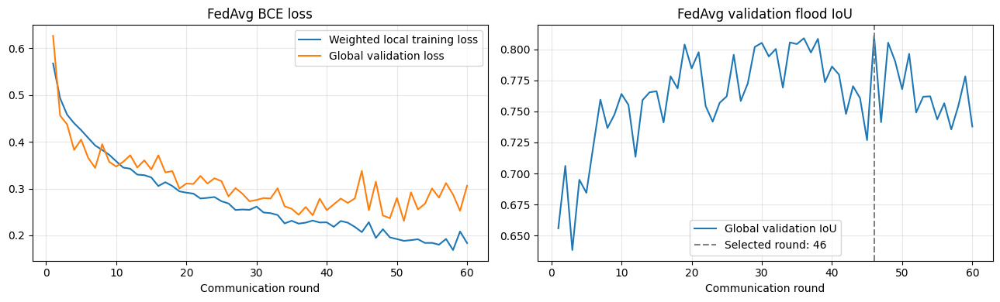


Results saved: /content/drive/MyDrive/DLP_Project/resnet50_fedavg_supervised/best_model_test_results.json


In [ ]:
fed_history_df = pd.read_csv(FED_HISTORY_PATH)

checkpoint = torch.load(
    FED_BEST_PATH, map_location="cpu", weights_only=False
)

assert checkpoint["config"] == fed_config, (
    "Checkpoint configuration does not match this experiment."
)

selected_round = checkpoint["round"]
selected_val_iou = checkpoint["best_val_iou"]

global_model.load_state_dict(checkpoint["model_state"])
global_model.eval()
del checkpoint

verified_fed_val = evaluate_federated(global_model, val_loader)

assert abs(verified_fed_val["iou"] - selected_val_iou) < 1e-4, (
    "Loaded checkpoint does not reproduce its validation IoU."
)

fed_test_metrics = evaluate_federated(global_model, test_loader)

print("Selected round:", selected_round)
print(f"Verified validation IoU: {verified_fed_val['iou']:.6f}")

print("\nHeld-out FedAvg test results:")
for name, value in fed_test_metrics.items():
    print(f"{name}: {value:.6f}")

fed_results = {
    "experiment": "fedavg_supervised_resnet50_unet",
    "completed_rounds": int(fed_history_df["round"].max()),
    "selected_round": selected_round,
    "local_epochs": LOCAL_EPOCHS,
    "client_sizes": {
        str(k): len(v) for k, v in client_datasets.items()
    },
    "test_images": len(test_dataset),
    "prediction_threshold": 0.5,
    "metric_aggregation": "pooled_pixel_counts",
    "validation_metrics": verified_fed_val,
    "test_metrics": fed_test_metrics,
    "recorded_round_compute_seconds": float(
        fed_history_df["seconds"].sum()
    ),
    "timing_note": "Excludes checkpoint and history saving overhead",
}

FED_RESULTS_PATH = FED_OUTPUT_DIR / "best_model_test_results.json"

with open(FED_RESULTS_PATH, "w") as file:
    json.dump(fed_results, file, indent=2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    fed_history_df["round"],
    fed_history_df["weighted_local_train_loss"],
    label="Weighted local training loss",
)
axes[0].plot(
    fed_history_df["round"],
    fed_history_df["val_loss"],
    label="Global validation loss",
)
axes[0].set_title("FedAvg BCE loss")
axes[0].set_xlabel("Communication round")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    fed_history_df["round"],
    fed_history_df["val_iou"],
    label="Global validation IoU",
)
axes[1].axvline(
    selected_round, color="gray", linestyle="--",
    label=f"Selected round: {selected_round}",
)
axes[1].set_title("FedAvg validation flood IoU")
axes[1].set_xlabel("Communication round")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(
    FED_OUTPUT_DIR / "learning_curves.png",
    dpi=150, bbox_inches="tight"
)
plt.show()

print("\nResults saved:", FED_RESULTS_PATH)

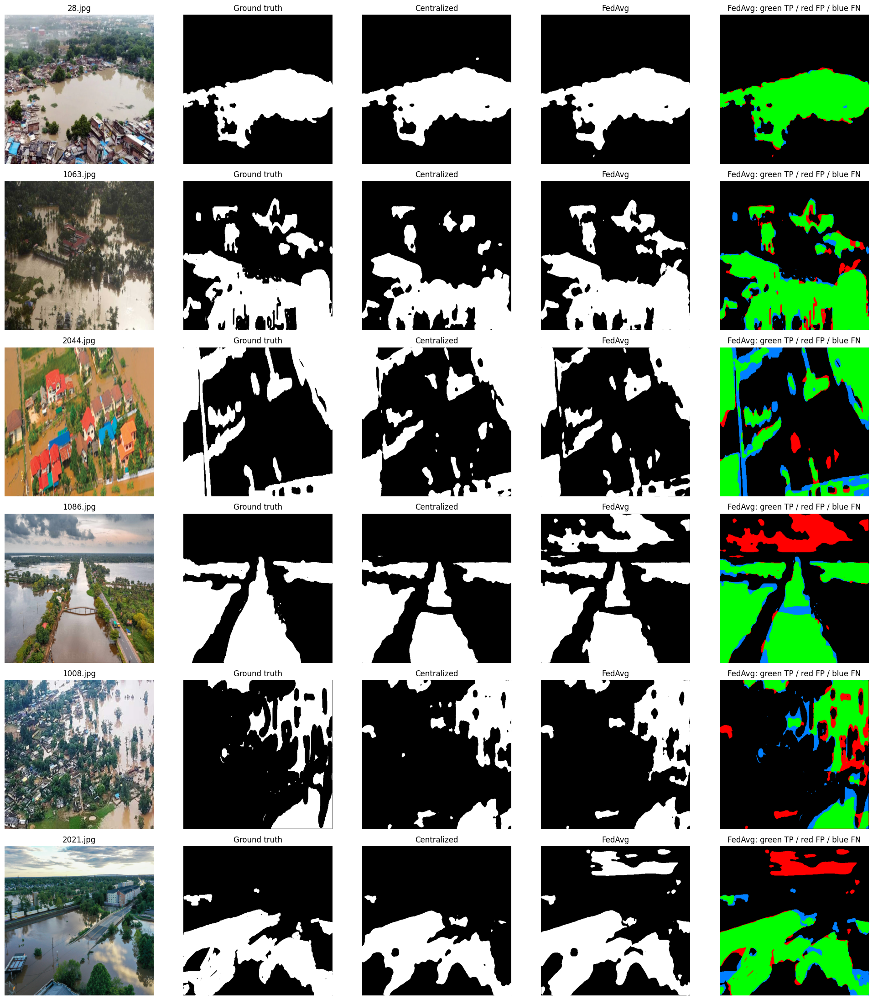

Comparison figure saved: /content/drive/MyDrive/DLP_Project/resnet50_fedavg_supervised/centralized_vs_fedavg_first6.png


,Metric,Centralized,FedAvg
0,loss,0.241252,0.266235
1,iou,0.812619,0.811681
2,precision,0.910837,0.895025
3,recall,0.882848,0.897084
4,f1,0.896624,0.896053
5,pixel_accuracy,0.908975,0.906937


In [ ]:
central_checkpoint = torch.load(
    BEST_PATH, map_location="cpu", weights_only=False
)
assert central_checkpoint["config"] == experiment_config
model.load_state_dict(central_checkpoint["model_state"])
model.eval()
del central_checkpoint

fed_checkpoint = torch.load(
    FED_BEST_PATH, map_location="cpu", weights_only=False
)
assert fed_checkpoint["config"] == fed_config
global_model.load_state_dict(fed_checkpoint["model_state"])
global_model.eval()
del fed_checkpoint

fig, axes = plt.subplots(6, 5, figsize=(20, 22))

with torch.inference_mode():
    for i in range(6):
        image, mask = test_dataset[i]
        input_image = image.unsqueeze(0).to(device)
        target = mask[0].numpy() > 0.5

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            central_prediction = (
                model(input_image)[0, 0] > 0
            ).cpu().numpy()

            fed_prediction = (
                global_model(input_image)[0, 0] > 0
            ).cpu().numpy()

        rgb = (
            image * IMAGENET_STD + IMAGENET_MEAN
        ).clamp(0, 1).permute(1, 2, 0).numpy()

        fed_errors = np.zeros((*target.shape, 3), dtype=np.float32)
        fed_errors[fed_prediction & target] = [0, 1, 0]
        fed_errors[fed_prediction & ~target] = [1, 0, 0]
        fed_errors[~fed_prediction & target] = [0, 0.5, 1]

        panels = [
            rgb, target, central_prediction, fed_prediction, fed_errors
        ]
        titles = [
            test_df.iloc[i]["Image"],
            "Ground truth",
            "Centralized",
            "FedAvg",
            "FedAvg: green TP / red FP / blue FN",
        ]

        for j, (panel, title) in enumerate(zip(panels, titles)):
            if j in (1, 2, 3):
                axes[i, j].imshow(
                    panel, cmap="gray", vmin=0, vmax=1
                )
            else:
                axes[i, j].imshow(panel)

            axes[i, j].set_title(title)
            axes[i, j].axis("off")

plt.tight_layout()

COMPARISON_PATH = FED_OUTPUT_DIR / "centralized_vs_fedavg_first6.png"
fig.savefig(COMPARISON_PATH, dpi=150, bbox_inches="tight")
plt.show()

comparison_table = pd.DataFrame({
    "Metric": list(test_metrics.keys()),
    "Centralized": [
        test_metrics[k] for k in test_metrics
    ],
    "FedAvg": [
        fed_test_metrics[k] for k in test_metrics
    ],
})
comparison_table.to_csv(
    FED_OUTPUT_DIR / "centralized_vs_fedavg_metrics.csv",
    index=False,
)

print("Comparison figure saved:", COMPARISON_PATH)
display(comparison_table)

## FedAvg with 20% labeled images

In [ ]:
LABEL_FRACTION = 0.20
LABEL_RECORD_DIR = CLIENT_RECORD_DIR / "labels_20pct_seed42"
LABEL_RECORD_DIR.mkdir(parents=True, exist_ok=True)

labeled_client_dfs = {}
unlabeled_client_dfs = {}
label_summary = []

for client_id in sorted(client_dfs):
    frame = client_dfs[client_id].reset_index(drop=True)

    rng = np.random.default_rng(SEED + client_id)
    shuffled_indices = rng.permutation(len(frame))

    labeled_count = max(1, int(round(LABEL_FRACTION * len(frame))))

    labeled_indices = shuffled_indices[:labeled_count]
    unlabeled_indices = shuffled_indices[labeled_count:]

    labeled_frame = frame.iloc[labeled_indices][
        ["Image", "Mask"]
    ].reset_index(drop=True)

    unlabeled_frame = frame.iloc[unlabeled_indices][
        ["Image"]
    ].reset_index(drop=True)

    labeled_names = set(labeled_frame["Image"])
    unlabeled_names = set(unlabeled_frame["Image"])

    assert labeled_names.isdisjoint(unlabeled_names)
    assert labeled_names | unlabeled_names == set(frame["Image"])
    assert "Mask" not in unlabeled_frame.columns

    labeled_client_dfs[client_id] = labeled_frame
    unlabeled_client_dfs[client_id] = unlabeled_frame

    label_summary.append({
        "Client": client_id,
        "Total training images": len(frame),
        "Labeled": len(labeled_frame),
        "Unlabeled": len(unlabeled_frame),
        "Actual labeled (%)": round(
            100 * len(labeled_frame) / len(frame), 2
        ),
    })

all_labeled = {
    name
    for frame in labeled_client_dfs.values()
    for name in frame["Image"]
}
all_unlabeled = {
    name
    for frame in unlabeled_client_dfs.values()
    for name in frame["Image"]
}

assert all_labeled.isdisjoint(all_unlabeled)
assert all_labeled | all_unlabeled == set(train_df["Image"])
assert (all_labeled | all_unlabeled).isdisjoint(val_df["Image"])
assert (all_labeled | all_unlabeled).isdisjoint(test_df["Image"])

label_records = {}

for client_id in sorted(client_dfs):
    label_records[f"client_{client_id}_labeled.csv"] = (
        labeled_client_dfs[client_id]
    )
    label_records[f"client_{client_id}_unlabeled.csv"] = (
        unlabeled_client_dfs[client_id]
    )

for filename, frame in label_records.items():
    path = LABEL_RECORD_DIR / filename
    if path.exists():
        pd.testing.assert_frame_equal(pd.read_csv(path), frame)

for filename, frame in label_records.items():
    path = LABEL_RECORD_DIR / filename
    if not path.exists():
        frame.to_csv(path, index=False)

display(pd.DataFrame(label_summary))

print("Total labeled:", len(all_labeled))
print("Total unlabeled:", len(all_unlabeled))
print("Validation/test overlap: none")
print("Saved records:", LABEL_RECORD_DIR)
print("\nNo models initialized or trained in this block.")

,Client,Total training images,Labeled,Unlabeled,Actual labeled (%)
0,1,108,22,86,20.37
1,2,51,10,41,19.61
2,3,58,12,46,20.69


Total labeled: 44
Total unlabeled: 173
Validation/test overlap: none
Saved records: /content/drive/MyDrive/DLP_Project/dataset_records/clients_non_iid_seed42/labels_20pct_seed42

No models initialized or trained in this block.


In [ ]:
LIMITED_OUTPUT_DIR = (
    ZIP_PATH.parent / "resnet50_fedavg_labeled20_control"
)
LIMITED_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LIMITED_ROUNDS = 60
LIMITED_LR = 0.001
LIMITED_BATCH_SIZE = 8

limited_datasets = {}
limited_loaders = {}
limited_generators = {}

for client_id in sorted(labeled_client_dfs):
    limited_datasets[client_id] = FloodDataset(
        labeled_client_dfs[client_id], DATA_ROOT
    )

    limited_generators[client_id] = (
        torch.Generator().manual_seed(SEED + client_id)
    )

    limited_loaders[client_id] = DataLoader(
        limited_datasets[client_id],
        batch_size=LIMITED_BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True,
        generator=limited_generators[client_id],
        drop_last=False,
    )

limited_steps_per_round = {
    client_id: len(client_loaders[client_id])
    for client_id in sorted(client_loaders)
}

limited_weights = client_weights.copy()

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

limited_global_model = copy.deepcopy(global_model)
limited_global_model.load_state_dict(fed_initial_state)
limited_global_model.to(device)
limited_global_model.eval()

for name, tensor in limited_global_model.state_dict().items():
    assert torch.equal(tensor.detach().cpu(), fed_initial_state[name]), (
        f"Initial state mismatch: {name}"
    )

for client_id in sorted(limited_loaders):
    print(
        f"Client {client_id}: "
        f"{len(limited_datasets[client_id])} labeled images | "
        f"{len(limited_loaders[client_id])} batches per labeled pass | "
        f"{limited_steps_per_round[client_id]} steps per round | "
        f"aggregation weight {limited_weights[client_id]:.6f}"
    )

print("\nRound budget:", LIMITED_ROUNDS)
print("Learning rate:", LIMITED_LR)
print("Initialization matches original federated model: passed")
print("Unlabeled images used by this control: none")
print("Results directory:", LIMITED_OUTPUT_DIR)
print("\nSetup complete. No training performed.")

Client 1: 22 labeled images | 3 batches per labeled pass | 14 steps per round | aggregation weight 0.497696
Client 2: 10 labeled images | 2 batches per labeled pass | 7 steps per round | aggregation weight 0.235023
Client 3: 12 labeled images | 2 batches per labeled pass | 8 steps per round | aggregation weight 0.267281

Round budget: 60
Learning rate: 0.001
Initialization matches original federated model: passed
Unlabeled images used by this control: none
Results directory: /content/drive/MyDrive/DLP_Project/resnet50_fedavg_labeled20_control

Setup complete. No training performed.


In [ ]:
def train_limited_client(global_state, client_id):
    local_model = copy.deepcopy(limited_global_model)
    local_model.load_state_dict(global_state)
    local_model.train()

    local_optimizer = torch.optim.Adam(
        local_model.parameters(),
        lr=LIMITED_LR,
        betas=(0.9, 0.999),
    )
    local_scaler = torch.amp.GradScaler("cuda")
    local_criterion = nn.BCEWithLogitsLoss()

    loader = limited_loaders[client_id]
    batch_iterator = iter(loader)

    total_loss = 0.0
    samples_seen = 0
    completed_steps = 0

    for _ in range(limited_steps_per_round[client_id]):
        try:
            batch_images, batch_masks = next(batch_iterator)
        except StopIteration:
            batch_iterator = iter(loader)
            batch_images, batch_masks = next(batch_iterator)

        batch_images = batch_images.to(device, non_blocking=True)
        batch_masks = batch_masks.to(device, non_blocking=True)

        local_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = local_model(batch_images)
            loss = local_criterion(logits, batch_masks)

        if not torch.isfinite(loss).item():
            raise RuntimeError(f"Non-finite loss: Client {client_id}")

        local_scaler.scale(loss).backward()
        local_scaler.unscale_(local_optimizer)

        for parameter in local_model.parameters():
            if parameter.grad is not None:
                if not torch.isfinite(parameter.grad).all().item():
                    raise RuntimeError(
                        f"Non-finite gradients: Client {client_id}"
                    )

        local_scaler.step(local_optimizer)
        local_scaler.update()

        count = batch_images.shape[0]
        total_loss += loss.item() * count
        samples_seen += count
        completed_steps += 1

    updated_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in local_model.state_dict().items()
    }

    for name, tensor in updated_state.items():
        if tensor.is_floating_point():
            assert torch.isfinite(tensor).all(), name

    del local_model, local_optimizer, local_scaler

    return (
        updated_state,
        total_loss / samples_seen,
        completed_steps,
        samples_seen,
    )


assert not globals().get("limited_history", []), (
    "The control's first round already ran. Share its output."
)
assert not (LIMITED_OUTPUT_DIR / "last_checkpoint.pt").exists(), (
    "A control checkpoint exists. Stop so we can resume it."
)

limited_round_start = time.time()
limited_global_model.load_state_dict(fed_initial_state)

control_client_states = {}
control_client_losses = {}
control_samples_seen = {}

for client_id in sorted(limited_loaders):
    state, mean_loss, steps, samples_seen = train_limited_client(
        fed_initial_state, client_id
    )

    assert steps == limited_steps_per_round[client_id]

    control_client_states[client_id] = state
    control_client_losses[client_id] = mean_loss
    control_samples_seen[client_id] = samples_seen

    print(
        f"Client {client_id} | "
        f"BCE loss: {mean_loss:.4f} | "
        f"Steps: {steps} | "
        f"Labeled image presentations: {samples_seen}",
        flush=True,
    )

control_aggregated = aggregate_fedavg(
    control_client_states, limited_weights
)
limited_global_model.load_state_dict(control_aggregated)

limited_val_metrics = evaluate_federated(
    limited_global_model, val_loader
)

limited_completed_rounds = 1
limited_best_round = 1
limited_best_val_iou = limited_val_metrics["iou"]

limited_history = [{
    "round": 1,
    "weighted_local_train_loss": sum(
        limited_weights[k] * control_client_losses[k]
        for k in limited_weights
    ),
    **{f"val_{k}": v for k, v in limited_val_metrics.items()},
    **{f"client_{k}_loss": v for k, v in control_client_losses.items()},
    **{
        f"client_{k}_presentations": v
        for k, v in control_samples_seen.items()
    },
    "seconds": time.time() - limited_round_start,
}]

print("\nLimited-label control: round 1 validation")
for name, value in limited_val_metrics.items():
    print(f"{name}: {value:.6f}")

print(f"\nRound duration: {limited_history[0]['seconds']:.1f}s")
print("Unique labeled training images: 44")
print("Unlabeled images used: 0")
print("Test set: not evaluated")

del control_client_states, control_aggregated, state
torch.cuda.empty_cache()

Client 1 | BCE loss: 0.5381 | Steps: 14 | Labeled image presentations: 104
Client 2 | BCE loss: 0.5982 | Steps: 7 | Labeled image presentations: 38
Client 3 | BCE loss: 0.5725 | Steps: 8 | Labeled image presentations: 48

Limited-label control: round 1 validation
loss: 0.641512
iou: 0.675555
precision: 0.756203
recall: 0.863657
f1: 0.806366
pixel_accuracy: 0.827020

Round duration: 21.7s
Unique labeled training images: 44
Unlabeled images used: 0
Test set: not evaluated


In [ ]:
LIMITED_LAST_PATH = LIMITED_OUTPUT_DIR / "last_checkpoint.pt"
LIMITED_BEST_PATH = LIMITED_OUTPUT_DIR / "best_checkpoint.pt"
LIMITED_HISTORY_PATH = LIMITED_OUTPUT_DIR / "training_history.csv"

limited_config = {
    "model": "ResNet50UNet",
    "encoder_weights": "IMAGENET1K_V1",
    "label_fraction_target": LABEL_FRACTION,
    "learning_rate": LIMITED_LR,
    "batch_size": LIMITED_BATCH_SIZE,
    "steps_per_client_per_round": limited_steps_per_round.copy(),
    "client_weights": limited_weights.copy(),
    "optimizer": "Adam_reset_each_client_each_round",
    "loss": "BCEWithLogitsLoss",
    "sampling": "cycle_shuffled_labeled_loader_to_fixed_step_budget",
    "aggregation": "sample_weighted_fedavg",
    "batchnorm_policy": "weighted_float_buffers_max_integer_counters",
    "image_size": list(IMAGE_SIZE),
    "mask_rule": "nonzero_is_flood",
    "seed": SEED,
    "labeled_clients": {
        k: frame.to_dict("records")
        for k, frame in labeled_client_dfs.items()
    },
    "unlabeled_clients_not_used": {
        k: frame.to_dict("records")
        for k, frame in unlabeled_client_dfs.items()
    },
    "validation": val_df[["Image", "Mask"]].to_dict("records"),
    "test": test_df[["Image", "Mask"]].to_dict("records"),
}


def save_limited_checkpoint(path):
    state = {
        "config": limited_config,
        "round": limited_completed_rounds,
        "model_state": {
            name: tensor.detach().cpu().clone()
            for name, tensor in limited_global_model.state_dict().items()
        },
        "best_val_iou": limited_best_val_iou,
        "best_round": limited_best_round,
        "history": limited_history.copy(),
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state(),
        "loader_rng": {
            k: generator.get_state()
            for k, generator in limited_generators.items()
        },
    }
    save_checkpoint(path, state)


if LIMITED_LAST_PATH.exists():
    checkpoint = torch.load(
        LIMITED_LAST_PATH, map_location="cpu", weights_only=False
    )
    assert checkpoint["config"] == limited_config, (
        "Control checkpoint configuration differs. Stop and share the error."
    )
    assert LIMITED_BEST_PATH.exists(), "Best control checkpoint is missing."

    limited_global_model.load_state_dict(checkpoint["model_state"])
    limited_completed_rounds = checkpoint["round"]
    limited_best_val_iou = checkpoint["best_val_iou"]
    limited_best_round = checkpoint["best_round"]
    limited_history = checkpoint["history"]

    random.setstate(checkpoint["python_rng"])
    np.random.set_state(checkpoint["numpy_rng"])
    torch.set_rng_state(checkpoint["torch_rng"])
    torch.cuda.set_rng_state(checkpoint["cuda_rng"])

    for k, rng_state in checkpoint["loader_rng"].items():
        limited_generators[k].set_state(rng_state)

    del checkpoint
    print(f"Resuming control after round {limited_completed_rounds}.")

else:
    assert limited_completed_rounds == 1
    assert not LIMITED_BEST_PATH.exists(), (
        "Best checkpoint exists without a latest checkpoint. Stop here."
    )

    save_limited_checkpoint(LIMITED_BEST_PATH)
    save_limited_checkpoint(LIMITED_LAST_PATH)
    print("Control round 1 saved. Continuing from round 2.")

pd.DataFrame(limited_history).to_csv(
    LIMITED_HISTORY_PATH, index=False
)

for round_index in range(limited_completed_rounds, LIMITED_ROUNDS):
    round_start = time.time()

    round_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in limited_global_model.state_dict().items()
    }

    control_states = {}
    control_losses = {}
    control_presentations = {}

    for client_id in sorted(limited_loaders):
        state, mean_loss, steps, samples_seen = train_limited_client(
            round_state, client_id
        )
        assert steps == limited_steps_per_round[client_id]

        control_states[client_id] = state
        control_losses[client_id] = mean_loss
        control_presentations[client_id] = samples_seen

    aggregated = aggregate_fedavg(control_states, limited_weights)
    limited_global_model.load_state_dict(aggregated)

    val_metrics = evaluate_federated(limited_global_model, val_loader)
    limited_completed_rounds = round_index + 1

    improved = val_metrics["iou"] > limited_best_val_iou
    if improved:
        limited_best_val_iou = val_metrics["iou"]
        limited_best_round = limited_completed_rounds

    row = {
        "round": limited_completed_rounds,
        "weighted_local_train_loss": sum(
            limited_weights[k] * control_losses[k]
            for k in limited_weights
        ),
        **{f"val_{k}": v for k, v in val_metrics.items()},
        **{f"client_{k}_loss": v for k, v in control_losses.items()},
        **{
            f"client_{k}_presentations": v
            for k, v in control_presentations.items()
        },
        "seconds": time.time() - round_start,
    }
    limited_history.append(row)

    if improved:
        save_limited_checkpoint(LIMITED_BEST_PATH)

    save_limited_checkpoint(LIMITED_LAST_PATH)
    pd.DataFrame(limited_history).to_csv(
        LIMITED_HISTORY_PATH, index=False
    )

    print(
        f"Control {limited_completed_rounds:02d}/{LIMITED_ROUNDS} | "
        f"Local loss {row['weighted_local_train_loss']:.4f} | "
        f"Val loss {val_metrics['loss']:.4f} | "
        f"Val IoU {val_metrics['iou']:.4f} | "
        f"Val F1 {val_metrics['f1']:.4f} | "
        f"{row['seconds']:.1f}s"
        + (" | BEST" if improved else ""),
        flush=True,
    )

    del round_state, control_states, aggregated, state

print(
    f"\nControl completed {limited_completed_rounds} rounds. "
    f"Best validation IoU: {limited_best_val_iou:.4f} "
    f"at round {limited_best_round}."
)
print("Test set: not evaluated")
print("Results directory:", LIMITED_OUTPUT_DIR)


Control round 1 saved. Continuing from round 2.
Control 02/60 | Local loss 0.4670 | Val loss 0.4931 | Val IoU 0.6492 | Val F1 0.7873 | 21.5s
Control 03/60 | Local loss 0.4570 | Val loss 0.4593 | Val IoU 0.6449 | Val F1 0.7841 | 23.1s
Control 04/60 | Local loss 0.4287 | Val loss 0.4352 | Val IoU 0.6650 | Val F1 0.7988 | 21.9s
Control 05/60 | Local loss 0.3992 | Val loss 0.4076 | Val IoU 0.6722 | Val F1 0.8039 | 23.0s
Control 06/60 | Local loss 0.3827 | Val loss 0.4152 | Val IoU 0.6526 | Val F1 0.7898 | 21.5s
Control 07/60 | Local loss 0.3659 | Val loss 0.3788 | Val IoU 0.7046 | Val F1 0.8267 | 23.0s | BEST
Control 08/60 | Local loss 0.3480 | Val loss 0.3903 | Val IoU 0.6657 | Val F1 0.7993 | 22.2s
Control 09/60 | Local loss 0.3372 | Val loss 0.3646 | Val IoU 0.6893 | Val F1 0.8160 | 23.4s
Control 10/60 | Local loss 0.3207 | Val loss 0.3636 | Val IoU 0.6959 | Val F1 0.8207 | 22.9s
Control 11/60 | Local loss 0.3016 | Val loss 0.3772 | Val IoU 0.6664 | Val F1 0.7998 | 21.5s
Control 12/60 |

Selected control round: 33

Verified validation metrics:
loss: 0.292687
iou: 0.767443
precision: 0.898187
recall: 0.840566
f1: 0.868422
pixel_accuracy: 0.893774


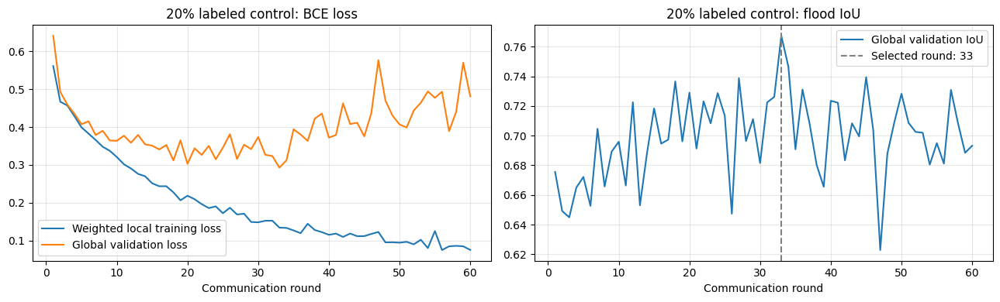


Control summary and curves saved.
Test set: not evaluated


In [ ]:
limited_history_df = pd.read_csv(LIMITED_HISTORY_PATH)

checkpoint = torch.load(
    LIMITED_BEST_PATH, map_location="cpu", weights_only=False
)

assert checkpoint["config"] == limited_config, (
    "Control checkpoint configuration does not match."
)

limited_selected_round = checkpoint["round"]
limited_saved_val_iou = checkpoint["best_val_iou"]

limited_global_model.load_state_dict(checkpoint["model_state"])
limited_global_model.eval()
del checkpoint

limited_verified_val = evaluate_federated(
    limited_global_model, val_loader
)

assert abs(
    limited_verified_val["iou"] - limited_saved_val_iou
) < 1e-4, "Control checkpoint validation score does not match."

print("Selected control round:", limited_selected_round)
print("\nVerified validation metrics:")
for name, value in limited_verified_val.items():
    print(f"{name}: {value:.6f}")

control_summary = {
    "experiment": "fedavg_supervised_labeled20_control",
    "completed_rounds": int(limited_history_df["round"].max()),
    "selected_round": limited_selected_round,
    "unique_labeled_images": 44,
    "unlabeled_images_used": 0,
    "steps_per_client_per_round": limited_steps_per_round,
    "validation_metrics": limited_verified_val,
    "test_evaluated": False,
}

with open(LIMITED_OUTPUT_DIR / "validation_summary.json", "w") as file:
    json.dump(control_summary, file, indent=2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    limited_history_df["round"],
    limited_history_df["weighted_local_train_loss"],
    label="Weighted local training loss",
)
axes[0].plot(
    limited_history_df["round"],
    limited_history_df["val_loss"],
    label="Global validation loss",
)
axes[0].set_title("20% labeled control: BCE loss")
axes[0].set_xlabel("Communication round")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    limited_history_df["round"],
    limited_history_df["val_iou"],
    label="Global validation IoU",
)
axes[1].axvline(
    limited_selected_round,
    color="gray", linestyle="--",
    label=f"Selected round: {limited_selected_round}",
)
axes[1].set_title("20% labeled control: flood IoU")
axes[1].set_xlabel("Communication round")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(
    LIMITED_OUTPUT_DIR / "learning_curves.png",
    dpi=150, bbox_inches="tight",
)
plt.show()

print("\nControl summary and curves saved.")
print("Test set: not evaluated")

## Student–teacher experiment (SSL)

In [ ]:
from torchvision.transforms import ColorJitter

strong_color_transform = ColorJitter(
    brightness=0.2,
    contrast=0.2,
    saturation=0.2,
    hue=0.05,
)


def normalize_rgb_pil(image):
    array = np.array(image, dtype=np.float32) / 255.0
    tensor = torch.from_numpy(array).permute(2, 0, 1).contiguous()
    return (tensor - IMAGENET_MEAN) / IMAGENET_STD


class UnlabeledFloodDataset(Dataset):
    def __init__(self, dataframe, data_root):
        assert list(dataframe.columns) == ["Image"], (
            "Unlabeled records must contain image filenames only."
        )
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.data_root = Path(data_root)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        filename = self.dataframe.iloc[index]["Image"]

        with Image.open(self.data_root / "Image" / filename) as image:
            image = image.convert("RGB").resize(
                IMAGE_SIZE, Image.Resampling.BILINEAR
            )

            weak_view = normalize_rgb_pil(image)
            strong_view = normalize_rgb_pil(
                strong_color_transform(image)
            )

        return weak_view, strong_view


ssl_labeled_loaders = {}
ssl_unlabeled_loaders = {}
ssl_labeled_generators = {}
ssl_unlabeled_generators = {}
ssl_unlabeled_datasets = {}

for client_id in sorted(client_dfs):

    ssl_labeled_generators[client_id] = (
        torch.Generator().manual_seed(SEED + client_id)
    )
    ssl_unlabeled_generators[client_id] = (
        torch.Generator().manual_seed(SEED + 1000 + client_id)
    )

    ssl_labeled_loaders[client_id] = DataLoader(
        limited_datasets[client_id],
        batch_size=LIMITED_BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True,
        generator=ssl_labeled_generators[client_id],
        drop_last=False,
    )

    ssl_unlabeled_datasets[client_id] = UnlabeledFloodDataset(
        unlabeled_client_dfs[client_id], DATA_ROOT
    )

    ssl_unlabeled_loaders[client_id] = DataLoader(
        ssl_unlabeled_datasets[client_id],
        batch_size=LIMITED_BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True,
        generator=ssl_unlabeled_generators[client_id],
        drop_last=False,
    )

saved_rng = torch.get_rng_state()

try:
    for client_id in sorted(client_dfs):
        weak, strong = ssl_unlabeled_datasets[client_id][0]

        assert weak.shape == strong.shape == (3, 512, 512)
        assert weak.dtype == strong.dtype == torch.float32
        assert torch.isfinite(weak).all()
        assert torch.isfinite(strong).all()

        print(
            f"Client {client_id}: "
            f"{len(limited_datasets[client_id])} labeled | "
            f"{len(ssl_unlabeled_datasets[client_id])} unlabeled | "
            f"view shape {tuple(weak.shape)}"
        )
finally:
    torch.set_rng_state(saved_rng)

print("\nWeak/strong view checks: passed")
print("Geometric alignment: unchanged between views")
print("Unlabeled masks read: none")
print("No training performed.")

Client 1: 22 labeled | 86 unlabeled | view shape (3, 512, 512)
Client 2: 10 labeled | 41 unlabeled | view shape (3, 512, 512)
Client 3: 12 labeled | 46 unlabeled | view shape (3, 512, 512)

Weak/strong view checks: passed
Geometric alignment: unchanged between views
Unlabeled masks read: none
No training performed.


In [ ]:
SSL_OUTPUT_DIR = ZIP_PATH.parent / "resnet50_fedavg_student_teacher_20pct"
SSL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SSL_ROUNDS = 60
SSL_LR = LIMITED_LR
SSL_CONFIDENCE = 0.95
SSL_EMA_DECAY = 0.99
SSL_WARMUP_ROUNDS = 5
SSL_RAMP_ROUNDS = 10
SSL_MAX_WEIGHT = 1.0

ssl_steps_per_round = limited_steps_per_round.copy()
ssl_weights = limited_weights.copy()


def unsupervised_weight(round_number):
    progress = (
        round_number - SSL_WARMUP_ROUNDS
    ) / SSL_RAMP_ROUNDS
    return SSL_MAX_WEIGHT * min(1.0, max(0.0, progress))


@torch.no_grad()
def update_ema_teacher(teacher, student, local_step):
    decay = min(SSL_EMA_DECAY, 1.0 - 1.0 / (local_step + 1))

    student_parameters = dict(student.named_parameters())
    for name, teacher_parameter in teacher.named_parameters():
        teacher_parameter.mul_(decay).add_(
            student_parameters[name], alpha=1.0 - decay
        )

    student_buffers = dict(student.named_buffers())
    for name, teacher_buffer in teacher.named_buffers():
        teacher_buffer.copy_(student_buffers[name])


def confidence_filtered_loss(student_logits, teacher_logits):
    probabilities = torch.sigmoid(teacher_logits.detach().float())
    confidence = torch.maximum(probabilities, 1.0 - probabilities)
    accepted = confidence >= SSL_CONFIDENCE
    pseudo_labels = (probabilities >= 0.5).float()

    pixel_losses = F.binary_cross_entropy_with_logits(
        student_logits.float(), pseudo_labels, reduction="none"
    )

    loss = (pixel_losses * accepted.float()).mean()

    return loss, accepted, pseudo_labels


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

ssl_global_model = copy.deepcopy(global_model)
ssl_global_model.load_state_dict(fed_initial_state)
ssl_global_model.to(device)
ssl_global_model.eval()

for name, tensor in ssl_global_model.state_dict().items():
    assert torch.equal(tensor.detach().cpu(), fed_initial_state[name]), name

example_student = torch.zeros(1, 1, 1, 3, requires_grad=True)
example_teacher = torch.tensor([[[[-10.0, 0.0, 10.0]]]])

example_loss, accepted, pseudo_labels = confidence_filtered_loss(
    example_student, example_teacher
)

assert accepted.flatten().tolist() == [True, False, True]
assert pseudo_labels.flatten().tolist() == [0.0, 1.0, 1.0]

example_loss.backward()
assert example_student.grad.flatten()[1].item() == 0.0
assert torch.isfinite(example_student.grad).all()

empty_loss, empty_accepted, _ = confidence_filtered_loss(
    torch.zeros(1, 1, 2, 2),
    torch.zeros(1, 1, 2, 2),
)
assert not empty_accepted.any()
assert empty_loss.item() == 0.0

print("Fresh initialization: verified")
print("Foreground/background confidence filtering: passed")
print("Rejected pixel gradient check: passed")
print("Zero accepted pixels handling: passed")

for round_number in [1, 5, 6, 10, 15, 60]:
    print(
        f"Round {round_number:02d}: "
        f"unsupervised weight = {unsupervised_weight(round_number):.2f}"
    )

print("\nTeacher: local EMA, reinitialized each round")
print("Server aggregation/evaluation: student model")
print("Results directory:", SSL_OUTPUT_DIR)
print("No training performed.")

del example_student, example_teacher, example_loss
del accepted, pseudo_labels, empty_loss, empty_accepted

Fresh initialization: verified
Foreground/background confidence filtering: passed
Rejected pixel gradient check: passed
Zero accepted pixels handling: passed
Round 01: unsupervised weight = 0.00
Round 05: unsupervised weight = 0.00
Round 06: unsupervised weight = 0.10
Round 10: unsupervised weight = 0.50
Round 15: unsupervised weight = 1.00
Round 60: unsupervised weight = 1.00

Teacher: local EMA, reinitialized each round
Server aggregation/evaluation: student model
Results directory: /content/drive/MyDrive/DLP_Project/resnet50_fedavg_student_teacher_20pct
No training performed.


In [ ]:
def train_ssl_client(global_state, client_id, round_number):
    student = copy.deepcopy(ssl_global_model)
    student.load_state_dict(global_state)
    student.train()

    teacher = copy.deepcopy(student)
    teacher.requires_grad_(False)
    teacher.eval()

    optimizer_local = torch.optim.Adam(
        student.parameters(),
        lr=SSL_LR,
        betas=(0.9, 0.999),
    )
    scaler_local = torch.amp.GradScaler("cuda")

    weight_u = unsupervised_weight(round_number)

    labeled_loader = ssl_labeled_loaders[client_id]
    labeled_iterator = iter(labeled_loader)

    unlabeled_iterator = (
        iter(ssl_unlabeled_loaders[client_id])
        if weight_u > 0 else None
    )

    supervised_sum = 0.0
    labeled_presentations = 0
    unsupervised_sum = 0.0
    unlabeled_pixels = 0
    unlabeled_presentations = 0
    accepted_pixels = 0
    accepted_flood_pixels = 0
    completed_steps = 0

    for step in range(ssl_steps_per_round[client_id]):
        try:
            labeled_images, labeled_masks = next(labeled_iterator)
        except StopIteration:
            labeled_iterator = iter(labeled_loader)
            labeled_images, labeled_masks = next(labeled_iterator)

        labeled_images = labeled_images.to(device, non_blocking=True)
        labeled_masks = labeled_masks.to(device, non_blocking=True)

        optimizer_local.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            labeled_logits = student(labeled_images)
            supervised_loss = F.binary_cross_entropy_with_logits(
                labeled_logits, labeled_masks
            )

        assert torch.isfinite(supervised_loss).item()
        scaler_local.scale(supervised_loss).backward()

        batch_count = labeled_images.shape[0]
        supervised_sum += supervised_loss.item() * batch_count
        labeled_presentations += batch_count

        if weight_u > 0:
            try:
                weak_images, strong_images = next(unlabeled_iterator)
            except StopIteration:
                unlabeled_iterator = iter(
                    ssl_unlabeled_loaders[client_id]
                )
                weak_images, strong_images = next(unlabeled_iterator)

            weak_images = weak_images.to(device, non_blocking=True)
            strong_images = strong_images.to(device, non_blocking=True)

            with torch.no_grad():
                with torch.autocast(
                    device_type="cuda", dtype=torch.float16
                ):
                    teacher_logits = teacher(weak_images)

            
            batchnorm_layers = [
                layer for layer in student.modules()
                if isinstance(layer, nn.modules.batchnorm._BatchNorm)
            ]

            for layer in batchnorm_layers:
                layer.eval()

            try:
                with torch.autocast(
                    device_type="cuda", dtype=torch.float16
                ):
                    strong_logits = student(strong_images)

                unsupervised_loss, accepted, pseudo_labels = (
                    confidence_filtered_loss(
                        strong_logits, teacher_logits
                    )
                )

                assert torch.isfinite(unsupervised_loss).item()
                scaler_local.scale(
                    weight_u * unsupervised_loss
                ).backward()

            finally:
                for layer in batchnorm_layers:
                    layer.train()

            pixel_count = accepted.numel()
            unsupervised_sum += (
                unsupervised_loss.item() * pixel_count
            )
            unlabeled_pixels += pixel_count
            unlabeled_presentations += weak_images.shape[0]
            accepted_pixels += accepted.sum().item()
            accepted_flood_pixels += (
                accepted & (pseudo_labels > 0.5)
            ).sum().item()

        scaler_local.unscale_(optimizer_local)

        for parameter in student.parameters():
            if parameter.grad is not None:
                if not torch.isfinite(parameter.grad).all().item():
                    raise RuntimeError(
                        f"Non-finite SSL gradients: "
                        f"Client {client_id}, round {round_number}"
                    )

        scaler_local.step(optimizer_local)
        scaler_local.update()

        completed_steps += 1
        update_ema_teacher(teacher, student, completed_steps)

    updated_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in student.state_dict().items()
    }

    for name, tensor in updated_state.items():
        if tensor.is_floating_point():
            assert torch.isfinite(tensor).all(), name

    metrics = {
        "supervised_loss": supervised_sum / labeled_presentations,
        "unsupervised_loss": (
            unsupervised_sum / unlabeled_pixels
            if unlabeled_pixels else 0.0
        ),
        "unsupervised_weight": weight_u,
        "pseudo_label_coverage": (
            accepted_pixels / unlabeled_pixels
            if unlabeled_pixels else 0.0
        ),
        "accepted_flood_fraction": (
            accepted_flood_pixels / accepted_pixels
            if accepted_pixels else 0.0
        ),
        "labeled_presentations": labeled_presentations,
        "unlabeled_presentations": unlabeled_presentations,
        "steps": completed_steps,
    }

    assert completed_steps == ssl_steps_per_round[client_id]

    del student, teacher, optimizer_local, scaler_local

    return updated_state, metrics


print("Local student–teacher training function defined.")
print("Supervised control step budgets retained:", ssl_steps_per_round)
print("Teacher gradients: disabled")
print("Student BatchNorm statistics: updated on labeled batches only")
print("No training performed.")

Local student–teacher training function defined.
Supervised control step budgets retained: {1: 14, 2: 7, 3: 8}
Teacher gradients: disabled
Student BatchNorm statistics: updated on labeled batches only
No training performed.


## Student-teacher runtime setup

In [16]:
from google.colab import drive
from pathlib import Path
import zipfile
import pandas as pd
import numpy as np
import torch
from PIL import Image

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/DLP_Project")
ZIP_PATH = PROJECT_DIR / "flood_area.zip"
DATA_RECORD_DIR = PROJECT_DIR / "dataset_records"

device = torch.device("cuda")
SEED = 42


extract_dir = Path("/content/dlp_flood_data")

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    metadata_paths = [
        name for name in archive.namelist()
        if Path(name).name.lower() == "metadata.csv"
        and "__MACOSX" not in name
    ]

    assert len(metadata_paths) == 1, (
        f"Expected one metadata.csv, found: {metadata_paths}"
    )

    archive.extractall(extract_dir)

DATA_ROOT = (extract_dir / metadata_paths[0]).parent


train_df = pd.read_csv(DATA_RECORD_DIR / "train_seed42.csv")
val_df = pd.read_csv(DATA_RECORD_DIR / "val_seed42.csv")
test_df = pd.read_csv(DATA_RECORD_DIR / "test_seed42.csv")

print("Device:", device)
print("Dataset root:", DATA_ROOT)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Image folder found:", (DATA_ROOT / "Image").is_dir())
print("Mask folder found:", (DATA_ROOT / "Mask").is_dir())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Dataset root: /content/dlp_flood_data
Training images: 217
Validation images: 29
Test images: 44
Image folder found: True
Mask folder found: True


In [17]:
from torch.utils.data import Dataset, DataLoader

IMAGE_SIZE = (512, 512)
BATCH_SIZE = 8

IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406], dtype=torch.float32
).view(3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225], dtype=torch.float32
).view(3, 1, 1)


class FloodDataset(Dataset):
    def __init__(self, dataframe, data_root):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.data_root = Path(data_root)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(self.data_root / "Image" / row["Image"]) as image:
            image = image.convert("RGB").resize(
                IMAGE_SIZE, Image.Resampling.BILINEAR
            )
            image = np.array(image, dtype=np.float32) / 255.0

        with Image.open(self.data_root / "Mask" / row["Mask"]) as mask:
            mask = mask.convert("L").resize(
                IMAGE_SIZE, Image.Resampling.NEAREST
            )
            mask = (np.array(mask) > 0).astype(np.float32)

        image = torch.from_numpy(image).permute(2, 0, 1).contiguous()
        image = (image - IMAGENET_MEAN) / IMAGENET_STD
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


CLIENT_RECORD_DIR = DATA_RECORD_DIR / "clients_non_iid_seed42"
LABEL_RECORD_DIR = CLIENT_RECORD_DIR / "labels_20pct_seed42"

client_dfs = {}
labeled_client_dfs = {}
unlabeled_client_dfs = {}

for client_id in (1, 2, 3):
    client_dfs[client_id] = pd.read_csv(
        CLIENT_RECORD_DIR / f"client_{client_id}.csv"
    )
    labeled_client_dfs[client_id] = pd.read_csv(
        LABEL_RECORD_DIR / f"client_{client_id}_labeled.csv"
    )
    unlabeled_client_dfs[client_id] = pd.read_csv(
        LABEL_RECORD_DIR / f"client_{client_id}_unlabeled.csv"
    )

    all_names = set(client_dfs[client_id]["Image"])
    labeled_names = set(labeled_client_dfs[client_id]["Image"])
    unlabeled_names = set(unlabeled_client_dfs[client_id]["Image"])

    assert labeled_names.isdisjoint(unlabeled_names)
    assert labeled_names | unlabeled_names == all_names

    print(
        f"Client {client_id}: "
        f"{len(labeled_names)} labeled, "
        f"{len(unlabeled_names)} unlabeled"
    )

val_dataset = FloodDataset(val_df, DATA_ROOT)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

sample_image, sample_mask = val_dataset[0]

print("\nValidation sample image:", tuple(sample_image.shape))
print("Validation sample mask:", tuple(sample_mask.shape))
print("Mask values:", torch.unique(sample_mask).tolist())
print("\nSaved client records loaded successfully.")

Client 1: 22 labeled, 86 unlabeled
Client 2: 10 labeled, 41 unlabeled
Client 3: 12 labeled, 46 unlabeled

Validation sample image: (3, 512, 512)
Validation sample mask: (1, 512, 512)
Mask values: [0.0, 1.0]

Saved client records loaded successfully.


In [18]:
import random
import copy
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50, ResNet50_Weights


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.conv = DoubleConv(in_channels + skip_channels, out_channels)

    def forward(self, x, skip):
        x = F.interpolate(
            x,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )
        return self.conv(torch.cat([x, skip], dim=1))


class ResNet50UNet(nn.Module):
    def __init__(self):
        super().__init__()

        encoder = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)

        self.stem = nn.Sequential(
            encoder.conv1, encoder.bn1, encoder.relu
        )
        self.pool = encoder.maxpool
        self.encoder1 = encoder.layer1
        self.encoder2 = encoder.layer2
        self.encoder3 = encoder.layer3
        self.encoder4 = encoder.layer4

        self.decoder4 = DecoderBlock(2048, 1024, 256)
        self.decoder3 = DecoderBlock(256, 512, 128)
        self.decoder2 = DecoderBlock(128, 256, 64)
        self.decoder1 = DecoderBlock(64, 64, 32)

        self.final_decoder = DoubleConv(32, 16)
        self.head = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        input_size = x.shape[-2:]

        s0 = self.stem(x)
        s1 = self.encoder1(self.pool(s0))
        s2 = self.encoder2(s1)
        s3 = self.encoder3(s2)
        bottleneck = self.encoder4(s3)

        x = self.decoder4(bottleneck, s3)
        x = self.decoder3(x, s2)
        x = self.decoder2(x, s1)
        x = self.decoder1(x, s0)

        x = F.interpolate(
            x,
            size=input_size,
            mode="bilinear",
            align_corners=False,
        )

        return self.head(self.final_decoder(x))


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

global_model = ResNet50UNet().to(device)
global_model.eval()

fed_initial_state = {
    name: tensor.detach().cpu().clone()
    for name, tensor in global_model.state_dict().items()
}

with torch.inference_mode():
    sample_output = global_model(sample_image.unsqueeze(0).to(device))

print("Device:", device)
print("Model output shape:", tuple(sample_output.shape))
print("Output values finite:", torch.isfinite(sample_output).all().item())
print("Initial model state saved in memory.")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 134MB/s]


Device: cuda
Model output shape: (1, 1, 512, 512)
Output values finite: True
Initial model state saved in memory.


In [19]:



client_datasets = {}
client_loaders = {}
limited_datasets = {}
limited_loaders = {}
limited_generators = {}

for client_id in (1, 2, 3):
    client_datasets[client_id] = FloodDataset(
        client_dfs[client_id], DATA_ROOT
    )

    client_loaders[client_id] = DataLoader(
        client_datasets[client_id],
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    limited_datasets[client_id] = FloodDataset(
        labeled_client_dfs[client_id], DATA_ROOT
    )

    limited_generators[client_id] = torch.Generator().manual_seed(
        SEED + client_id
    )

    limited_loaders[client_id] = DataLoader(
        limited_datasets[client_id],
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=limited_generators[client_id],
        drop_last=False,
    )

limited_steps_per_round = {
    client_id: len(client_loaders[client_id])
    for client_id in (1, 2, 3)
}

limited_weights = {
    client_id: len(client_datasets[client_id]) / len(train_df)
    for client_id in (1, 2, 3)
}

for client_id in (1, 2, 3):
    print(
        f"Client {client_id} | "
        f"Labeled: {len(limited_datasets[client_id])} | "
        f"Steps per round: {limited_steps_per_round[client_id]} | "
        f"Aggregation weight: {limited_weights[client_id]:.6f}"
    )

print("\nGPU client loaders ready.")

Client 1 | Labeled: 22 | Steps per round: 14 | Aggregation weight: 0.497696
Client 2 | Labeled: 10 | Steps per round: 7 | Aggregation weight: 0.235023
Client 3 | Labeled: 12 | Steps per round: 8 | Aggregation weight: 0.267281

GPU client loaders ready.


In [20]:
LIMITED_LR = 0.001

limited_global_model = copy.deepcopy(global_model)
limited_global_model.load_state_dict(fed_initial_state)
limited_global_model.to(device)


def train_limited_client_cpu(global_state, client_id):
    local_model = copy.deepcopy(limited_global_model)
    local_model.load_state_dict(global_state)
    local_model.train()

    optimizer = torch.optim.Adam(
        local_model.parameters(),
        lr=LIMITED_LR,
        betas=(0.9, 0.999),
    )

    criterion = nn.BCEWithLogitsLoss()
    loader = limited_loaders[client_id]
    batch_iterator = iter(loader)

    total_loss = 0.0
    samples_seen = 0

    for step in range(limited_steps_per_round[client_id]):
        try:
            batch_images, batch_masks = next(batch_iterator)
        except StopIteration:
            batch_iterator = iter(loader)
            batch_images, batch_masks = next(batch_iterator)

        batch_images = batch_images.to(device)
        batch_masks = batch_masks.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = local_model(batch_images)
        loss = criterion(logits, batch_masks)

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Non-finite loss for client {client_id}"
            )

        loss.backward()

        for parameter in local_model.parameters():
            if parameter.grad is not None:
                if not torch.isfinite(parameter.grad).all().item():
                    raise RuntimeError(
                        f"Non-finite gradients for client {client_id}"
                    )

        optimizer.step()

        count = batch_images.shape[0]
        total_loss += loss.item() * count
        samples_seen += count

    updated_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in local_model.state_dict().items()
    }

    return (
        updated_state,
        total_loss / samples_seen,
        limited_steps_per_round[client_id],
        samples_seen,
    )


print("CPU control training function ready.")

CPU control training function ready.


In [21]:
SSL_OUTPUT_DIR = PROJECT_DIR / "resnet50_fedavg_student_teacher_20pct"
SSL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SSL_ROUNDS = 60
SSL_LR = LIMITED_LR
SSL_CONFIDENCE = 0.95
SSL_EMA_DECAY = 0.99
SSL_WARMUP_ROUNDS = 5
SSL_RAMP_ROUNDS = 10
SSL_MAX_WEIGHT = 1.0

ssl_steps_per_round = limited_steps_per_round.copy()
ssl_weights = limited_weights.copy()


def unsupervised_weight(round_number):
    progress = (
        round_number - SSL_WARMUP_ROUNDS
    ) / SSL_RAMP_ROUNDS

    return SSL_MAX_WEIGHT * min(1.0, max(0.0, progress))


@torch.no_grad()
def update_ema_teacher(teacher, student, local_step):
    decay = min(
        SSL_EMA_DECAY,
        1.0 - 1.0 / (local_step + 1)
    )

    student_parameters = dict(student.named_parameters())

    for name, teacher_parameter in teacher.named_parameters():
        teacher_parameter.mul_(decay).add_(
            student_parameters[name],
            alpha=1.0 - decay,
        )

    student_buffers = dict(student.named_buffers())

    for name, teacher_buffer in teacher.named_buffers():
        teacher_buffer.copy_(student_buffers[name])


def confidence_filtered_loss(student_logits, teacher_logits):
    probabilities = torch.sigmoid(teacher_logits.detach().float())
    confidence = torch.maximum(probabilities, 1.0 - probabilities)

    accepted = confidence >= SSL_CONFIDENCE
    pseudo_labels = (probabilities >= 0.5).float()

    pixel_losses = F.binary_cross_entropy_with_logits(
        student_logits.float(),
        pseudo_labels,
        reduction="none",
    )

    loss = (pixel_losses * accepted.float()).mean()

    return loss, accepted, pseudo_labels


ssl_global_model = copy.deepcopy(global_model)
ssl_global_model.load_state_dict(fed_initial_state)
ssl_global_model.to(device)
ssl_global_model.eval()

example_student = torch.zeros(1, 1, 1, 3, requires_grad=True)
example_teacher = torch.tensor([[[[-10.0, 0.0, 10.0]]]])

example_loss, accepted, pseudo_labels = confidence_filtered_loss(
    example_student,
    example_teacher,
)

assert accepted.flatten().tolist() == [True, False, True]
assert pseudo_labels.flatten().tolist() == [0.0, 1.0, 1.0]

example_loss.backward()

assert example_student.grad.flatten()[1].item() == 0.0
assert torch.isfinite(example_student.grad).all()

print("Student–teacher settings ready.")
print("Confidence filtering check: passed")
print("Rejected-pixel gradient check: passed")

for round_number in [1, 5, 6, 10, 15, 60]:
    print(
        f"Round {round_number:02d} | "
        f"Unsupervised weight: {unsupervised_weight(round_number):.2f}"
    )

Student–teacher settings ready.
Confidence filtering check: passed
Rejected-pixel gradient check: passed
Round 01 | Unsupervised weight: 0.00
Round 05 | Unsupervised weight: 0.00
Round 06 | Unsupervised weight: 0.10
Round 10 | Unsupervised weight: 0.50
Round 15 | Unsupervised weight: 1.00
Round 60 | Unsupervised weight: 1.00


In [22]:
from torchvision.transforms import ColorJitter

strong_color_transform = ColorJitter(
    brightness=0.3,
    contrast=0.3,
    saturation=0.3,
    hue=0.05,
)


def normalize_rgb_pil(image):
    image = image.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
    image = np.array(image, dtype=np.float32) / 255.0
    image = torch.from_numpy(image).permute(2, 0, 1).contiguous()

    return (image - IMAGENET_MEAN) / IMAGENET_STD


class UnlabeledFloodDataset(Dataset):
    def __init__(self, dataframe, data_root):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.data_root = Path(data_root)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(self.data_root / "Image" / row["Image"]) as image:
            image = image.convert("RGB")
            weak_image = normalize_rgb_pil(image)
            strong_image = normalize_rgb_pil(strong_color_transform(image))

        return weak_image, strong_image


ssl_labeled_loaders = {}
ssl_unlabeled_loaders = {}
ssl_labeled_generators = {}
ssl_unlabeled_generators = {}

for client_id in (1, 2, 3):
    ssl_labeled_generators[client_id] = torch.Generator().manual_seed(
        SEED + client_id
    )

    ssl_unlabeled_generators[client_id] = torch.Generator().manual_seed(
        SEED + 1000 + client_id
    )

    ssl_labeled_loaders[client_id] = DataLoader(
        limited_datasets[client_id],
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=ssl_labeled_generators[client_id],
        drop_last=False,
    )

    unlabeled_dataset = UnlabeledFloodDataset(
        unlabeled_client_dfs[client_id],
        DATA_ROOT,
    )

    ssl_unlabeled_loaders[client_id] = DataLoader(
        unlabeled_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=ssl_unlabeled_generators[client_id],
        drop_last=False,
    )


def train_ssl_client_cpu(global_state, client_id, round_number):
    student = copy.deepcopy(ssl_global_model)
    student.load_state_dict(global_state)
    student.train()

    teacher = copy.deepcopy(student)
    teacher.requires_grad_(False)
    teacher.eval()

    optimizer = torch.optim.Adam(
        student.parameters(),
        lr=SSL_LR,
        betas=(0.9, 0.999),
    )

    weight_u = unsupervised_weight(round_number)

    labeled_loader = ssl_labeled_loaders[client_id]
    labeled_iterator = iter(labeled_loader)

    unlabeled_loader = ssl_unlabeled_loaders[client_id]
    unlabeled_iterator = iter(unlabeled_loader) if weight_u > 0 else None

    supervised_sum = 0.0
    labeled_presentations = 0
    unsupervised_sum = 0.0
    unlabeled_pixels = 0
    unlabeled_presentations = 0
    accepted_pixels = 0
    accepted_flood_pixels = 0

    for step in range(ssl_steps_per_round[client_id]):
        try:
            labeled_images, labeled_masks = next(labeled_iterator)
        except StopIteration:
            labeled_iterator = iter(labeled_loader)
            labeled_images, labeled_masks = next(labeled_iterator)

        labeled_images = labeled_images.to(device)
        labeled_masks = labeled_masks.to(device)

        optimizer.zero_grad(set_to_none=True)

        labeled_logits = student(labeled_images)
        supervised_loss = F.binary_cross_entropy_with_logits(
            labeled_logits, labeled_masks
        )

        if not torch.isfinite(supervised_loss).item():
            raise RuntimeError(
                f"Non-finite supervised loss for client {client_id}"
            )

        supervised_loss.backward()

        batch_count = labeled_images.shape[0]
        supervised_sum += supervised_loss.item() * batch_count
        labeled_presentations += batch_count

        if weight_u > 0:
            try:
                weak_images, strong_images = next(unlabeled_iterator)
            except StopIteration:
                unlabeled_iterator = iter(unlabeled_loader)
                weak_images, strong_images = next(unlabeled_iterator)

            weak_images = weak_images.to(device)
            strong_images = strong_images.to(device)

            with torch.no_grad():
                teacher_logits = teacher(weak_images)

            batchnorm_layers = [
                layer for layer in student.modules()
                if isinstance(layer, nn.modules.batchnorm._BatchNorm)
            ]

            for layer in batchnorm_layers:
                layer.eval()

            try:
                strong_logits = student(strong_images)

                unsupervised_loss, accepted, pseudo_labels = (
                    confidence_filtered_loss(
                        strong_logits, teacher_logits
                    )
                )

                if not torch.isfinite(unsupervised_loss).item():
                    raise RuntimeError(
                        f"Non-finite SSL loss for client {client_id}"
                    )

                (weight_u * unsupervised_loss).backward()

            finally:
                for layer in batchnorm_layers:
                    layer.train()

            pixel_count = accepted.numel()

            unsupervised_sum += unsupervised_loss.item() * pixel_count
            unlabeled_pixels += pixel_count
            unlabeled_presentations += weak_images.shape[0]
            accepted_pixels += accepted.sum().item()
            accepted_flood_pixels += (
                accepted & (pseudo_labels > 0.5)
            ).sum().item()

        for parameter in student.parameters():
            if parameter.grad is not None:
                if not torch.isfinite(parameter.grad).all().item():
                    raise RuntimeError(
                        f"Non-finite gradients for client {client_id}"
                    )

        optimizer.step()
        update_ema_teacher(teacher, student, step + 1)

    updated_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in student.state_dict().items()
    }

    metrics = {
        "supervised_loss": supervised_sum / labeled_presentations,
        "unsupervised_loss": (
            unsupervised_sum / unlabeled_pixels
            if unlabeled_pixels else 0.0
        ),
        "unsupervised_weight": weight_u,
        "pseudo_label_coverage": (
            accepted_pixels / unlabeled_pixels
            if unlabeled_pixels else 0.0
        ),
        "accepted_flood_fraction": (
            accepted_flood_pixels / accepted_pixels
            if accepted_pixels else 0.0
        ),
        "labeled_presentations": labeled_presentations,
        "unlabeled_presentations": unlabeled_presentations,
        "steps": ssl_steps_per_round[client_id],
    }

    return updated_state, metrics


for client_id in (1, 2, 3):
    print(
        f"Client {client_id} | "
        f"Labeled: {len(ssl_labeled_loaders[client_id].dataset)} | "
        f"Unlabeled: {len(ssl_unlabeled_loaders[client_id].dataset)}"
    )

print("\nCPU student–teacher function ready. No training performed.")

Client 1 | Labeled: 22 | Unlabeled: 86
Client 2 | Labeled: 10 | Unlabeled: 41
Client 3 | Labeled: 12 | Unlabeled: 46

CPU student–teacher function ready. No training performed.


In [23]:
strong_color_transform = ColorJitter(
    brightness=0.2,
    contrast=0.2,
    saturation=0.2,
    hue=0.05,
)


class UnlabeledFloodDataset(Dataset):
    def __init__(self, dataframe, data_root):
        assert list(dataframe.columns) == ["Image"], (
            "Unlabeled records must contain image filenames only."
        )
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.data_root = Path(data_root)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        filename = self.dataframe.iloc[index]["Image"]

        with Image.open(self.data_root / "Image" / filename) as image:
            image = image.convert("RGB").resize(
                IMAGE_SIZE, Image.Resampling.BILINEAR
            )

            weak_view = normalize_rgb_pil(image)
            strong_view = normalize_rgb_pil(
                strong_color_transform(image)
            )

        return weak_view, strong_view


ssl_unlabeled_loaders = {}

for client_id in (1, 2, 3):
    ssl_unlabeled_generators[client_id] = torch.Generator().manual_seed(
        SEED + 1000 + client_id
    )

    dataset = UnlabeledFloodDataset(
        unlabeled_client_dfs[client_id],
        DATA_ROOT,
    )

    ssl_unlabeled_loaders[client_id] = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=ssl_unlabeled_generators[client_id],
        drop_last=False,
    )

    print(f"Client {client_id}: {len(dataset)} unlabeled images")

print("\nOriginal strong-view settings restored.")


Client 1: 86 unlabeled images
Client 2: 41 unlabeled images
Client 3: 46 unlabeled images

Original strong-view settings restored.


## Student-teacher training

In [ ]:
import os
import time

SSL_LAST_PATH = SSL_OUTPUT_DIR / "last_checkpoint.pt"
SSL_BEST_PATH = SSL_OUTPUT_DIR / "best_checkpoint.pt"

if SSL_LAST_PATH.exists() or SSL_BEST_PATH.exists():
    raise FileExistsError(
        "An SSL checkpoint already exists. Stop and share this message "
        "so we can resume it."
    )


def aggregate_ssl_states(client_states, weights):
    client_ids = sorted(client_states)

    assert set(client_ids) == set(weights)
    assert abs(sum(weights.values()) - 1.0) < 1e-8

    reference = client_states[client_ids[0]]
    aggregated = {}

    for name, reference_tensor in reference.items():
        tensors = [client_states[k][name] for k in client_ids]

        if reference_tensor.is_floating_point():
            result = torch.zeros_like(reference_tensor)

            for client_id in client_ids:
                result.add_(
                    client_states[client_id][name],
                    alpha=weights[client_id],
                )

            assert torch.isfinite(result).all(), name

        else:
            assert name.endswith("num_batches_tracked"), name
            result = torch.stack(tensors).amax(dim=0)

        aggregated[name] = result

    return aggregated


def evaluate_ssl_cpu(network, loader):
    network.eval()

    total_loss = 0.0
    samples_seen = 0
    counts = torch.zeros(4, dtype=torch.int64)

    with torch.inference_mode():
        for batch_images, batch_masks in loader:
            batch_images = batch_images.to(device)
            batch_masks = batch_masks.to(device)

            logits = network(batch_images)
            loss = F.binary_cross_entropy_with_logits(logits, batch_masks)

            assert torch.isfinite(logits).all()
            assert torch.isfinite(loss).item()

            count = batch_images.shape[0]
            total_loss += loss.item() * count
            samples_seen += count

            predicted = logits > 0
            target = batch_masks > 0.5

            counts += torch.stack([
                (predicted & target).sum(),
                (predicted & ~target).sum(),
                (~predicted & target).sum(),
                (~predicted & ~target).sum(),
            ]).cpu()

    tp, fp, fn, tn = counts.tolist()

    return {
        "loss": total_loss / samples_seen,
        "iou": tp / max(tp + fp + fn, 1),
        "precision": tp / max(tp + fp, 1),
        "recall": tp / max(tp + fn, 1),
        "f1": 2 * tp / max(2 * tp + fp + fn, 1),
        "pixel_accuracy": (tp + tn) / max(tp + fp + fn + tn, 1),
    }


def save_ssl_checkpoint(path, state):
    temporary_path = path.with_suffix(".tmp")
    torch.save(state, temporary_path)
    os.replace(temporary_path, path)



random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

for client_id in (1, 2, 3):
    ssl_labeled_generators[client_id].manual_seed(SEED + client_id)
    ssl_unlabeled_generators[client_id].manual_seed(
        SEED + 1000 + client_id
    )

ssl_global_model.load_state_dict(fed_initial_state)

round_start = time.time()
client_states = {}
client_metrics = {}

for client_id in (1, 2, 3):
    print(f"Training client {client_id}...", flush=True)
    client_start = time.time()

    state, metrics = train_ssl_client_cpu(
        fed_initial_state,
        client_id,
        round_number=1,
    )

    client_states[client_id] = state
    client_metrics[client_id] = metrics

    print(
        f"Client {client_id} | "
        f"Loss: {metrics['supervised_loss']:.6f} | "
        f"Steps: {metrics['steps']} | "
        f"Minutes: {(time.time() - client_start) / 60:.1f}",
        flush=True,
    )

aggregated_state = aggregate_ssl_states(client_states, ssl_weights)
ssl_global_model.load_state_dict(aggregated_state)

print("\nEvaluating validation set...", flush=True)
val_metrics = evaluate_ssl_cpu(ssl_global_model, val_loader)

ssl_history = [{
    "round": 1,
    "unsupervised_weight": 0.0,
    "weighted_supervised_loss": sum(
        ssl_weights[k] * client_metrics[k]["supervised_loss"]
        for k in ssl_weights
    ),
    **{f"val_{name}": value for name, value in val_metrics.items()},
    "seconds": time.time() - round_start,
}]

checkpoint = {
    "round": 1,
    "model_state": aggregated_state,
    "best_val_iou": val_metrics["iou"],
    "best_round": 1,
    "history": ssl_history,
    "python_rng": random.getstate(),
    "numpy_rng": np.random.get_state(),
    "torch_rng": torch.get_rng_state(),
    "labeled_generator_states": {
        k: generator.get_state()
        for k, generator in ssl_labeled_generators.items()
    },
    "unlabeled_generator_states": {
        k: generator.get_state()
        for k, generator in ssl_unlabeled_generators.items()
    },
    "settings": {
        "seed": SEED,
        "device": "cpu",
        "learning_rate": SSL_LR,
        "batch_size": BATCH_SIZE,
        "warmup_rounds": SSL_WARMUP_ROUNDS,
        "ramp_rounds": SSL_RAMP_ROUNDS,
        "confidence": SSL_CONFIDENCE,
        "ema_decay": SSL_EMA_DECAY,
    },
}

save_ssl_checkpoint(SSL_LAST_PATH, checkpoint)
save_ssl_checkpoint(SSL_BEST_PATH, checkpoint)

print("\nRound 1 validation results")
for name, value in val_metrics.items():
    print(f"{name}: {value:.6f}")

print(f"\nRound duration: {(time.time() - round_start) / 60:.1f} minutes")
print("Saved:", SSL_LAST_PATH.name)
print("Saved:", SSL_BEST_PATH.name)
print("Unlabeled images used in this warm-up round: 0")
print("Test set: not evaluated")

Training client 1...
Client 1 | Loss: 0.534347 | Steps: 14 | Minutes: 13.0
Training client 2...
Client 2 | Loss: 0.592215 | Steps: 7 | Minutes: 4.6
Training client 3...
Client 3 | Loss: 0.574500 | Steps: 8 | Minutes: 5.8

Evaluating validation set...

Round 1 validation results
loss: 0.640573
iou: 0.694140
precision: 0.773050
recall: 0.871799
f1: 0.819460
pixel_accuracy: 0.839798

Round duration: 24.4 minutes
Saved: last_checkpoint.pt
Saved: best_checkpoint.pt
Unlabeled images used in this warm-up round: 0
Test set: not evaluated


In [24]:
import os
import time
import torch.nn.functional as F

assert torch.cuda.is_available(), "Connect to a GPU runtime first."

device = torch.device("cuda")

global_model = global_model.to(device)
limited_global_model = limited_global_model.to(device)
ssl_global_model = ssl_global_model.to(device)

SSL_LAST_PATH = SSL_OUTPUT_DIR / "last_checkpoint.pt"
SSL_BEST_PATH = SSL_OUTPUT_DIR / "best_checkpoint.pt"


def aggregate_ssl_states(client_states, weights):
    client_ids = sorted(client_states)

    assert set(client_ids) == set(weights)
    assert abs(sum(weights.values()) - 1.0) < 1e-8

    reference = client_states[client_ids[0]]
    aggregated = {}

    for name, reference_tensor in reference.items():
        tensors = [client_states[k][name] for k in client_ids]

        if reference_tensor.is_floating_point():
            result = torch.zeros_like(reference_tensor)

            for client_id in client_ids:
                result.add_(
                    client_states[client_id][name],
                    alpha=weights[client_id],
                )

            assert torch.isfinite(result).all(), name

        else:
            assert name.endswith("num_batches_tracked"), name
            result = torch.stack(tensors).amax(dim=0)

        aggregated[name] = result

    return aggregated


def evaluate_ssl_cpu(network, loader):
    network.eval()

    total_loss = 0.0
    samples_seen = 0
    counts = torch.zeros(4, dtype=torch.int64)

    with torch.inference_mode():
        for batch_images, batch_masks in loader:
            batch_images = batch_images.to(device)
            batch_masks = batch_masks.to(device)

            logits = network(batch_images)
            loss = F.binary_cross_entropy_with_logits(
                logits, batch_masks
            )

            assert torch.isfinite(logits).all()
            assert torch.isfinite(loss).item()

            count = batch_images.shape[0]
            total_loss += loss.item() * count
            samples_seen += count

            predicted = logits > 0
            target = batch_masks > 0.5

            counts += torch.stack([
                (predicted & target).sum(),
                (predicted & ~target).sum(),
                (~predicted & target).sum(),
                (~predicted & ~target).sum(),
            ]).cpu()

    tp, fp, fn, tn = counts.tolist()

    return {
        "loss": total_loss / samples_seen,
        "iou": tp / max(tp + fp + fn, 1),
        "precision": tp / max(tp + fp, 1),
        "recall": tp / max(tp + fn, 1),
        "f1": 2 * tp / max(2 * tp + fp + fn, 1),
        "pixel_accuracy": (tp + tn) / max(tp + fp + fn + tn, 1),
    }


def save_ssl_checkpoint(path, state):
    temporary_path = path.with_suffix(".tmp")
    torch.save(state, temporary_path)
    os.replace(temporary_path, path)


assert SSL_LAST_PATH.is_file(), f"Checkpoint missing: {SSL_LAST_PATH}"

saved_checkpoint = torch.load(
    SSL_LAST_PATH,
    map_location="cpu",
    weights_only=False,
)

print("GPU:", torch.cuda.get_device_name(0))
print("Last completed SSL round:", saved_checkpoint["round"])
print("Best validation IoU:", saved_checkpoint["best_val_iou"])
print("Best round:", saved_checkpoint["best_round"])
print("Best checkpoint found:", SSL_BEST_PATH.is_file())

GPU: Tesla T4
Last completed SSL round: 1
Best validation IoU: 0.6941400754327286
Best round: 1
Best checkpoint found: True


In [25]:
import random
import numpy as np
import time

checkpoint = torch.load(
    SSL_LAST_PATH,
    map_location="cpu",
    weights_only=False,
)

completed_round = checkpoint["round"]
next_round = completed_round + 1

assert next_round <= SSL_ROUNDS, "All SSL rounds are complete."

ssl_global_model.load_state_dict(checkpoint["model_state"])
ssl_history = list(checkpoint["history"])
best_val_iou = checkpoint["best_val_iou"]
best_round = checkpoint["best_round"]


random.setstate(checkpoint["python_rng"])
np.random.set_state(checkpoint["numpy_rng"])
torch.set_rng_state(checkpoint["torch_rng"])

for client_id in (1, 2, 3):
    ssl_labeled_generators[client_id].set_state(
        checkpoint["labeled_generator_states"][client_id]
    )
    ssl_unlabeled_generators[client_id].set_state(
        checkpoint["unlabeled_generator_states"][client_id]
    )



if "cuda_rng" in checkpoint:
    torch.cuda.set_rng_state(checkpoint["cuda_rng"])
else:
    torch.cuda.manual_seed_all(SEED)

round_start = time.time()

round_start_state = {
    name: tensor.detach().cpu().clone()
    for name, tensor in ssl_global_model.state_dict().items()
}

client_states = {}
client_metrics = {}

print(f"Starting round {next_round}/{SSL_ROUNDS}", flush=True)
print(
    f"Unsupervised weight: {unsupervised_weight(next_round):.2f}",
    flush=True,
)

for client_id in (1, 2, 3):
    client_start = time.time()
    print(f"\nTraining client {client_id}...", flush=True)

    state, metrics = train_ssl_client_cpu(
        round_start_state,
        client_id,
        round_number=next_round,
    )

    client_states[client_id] = state
    client_metrics[client_id] = metrics

    print(
        f"Client {client_id} | "
        f"Supervised loss: {metrics['supervised_loss']:.6f} | "
        f"Unlabeled presentations: {metrics['unlabeled_presentations']} | "
        f"Seconds: {time.time() - client_start:.1f}",
        flush=True,
    )

aggregated_state = aggregate_ssl_states(client_states, ssl_weights)
ssl_global_model.load_state_dict(aggregated_state)

print("\nEvaluating validation set...", flush=True)
val_metrics = evaluate_ssl_cpu(ssl_global_model, val_loader)

improved = val_metrics["iou"] > best_val_iou

if improved:
    best_val_iou = val_metrics["iou"]
    best_round = next_round

row = {
    "round": next_round,
    "unsupervised_weight": unsupervised_weight(next_round),
    "weighted_supervised_loss": sum(
        ssl_weights[k] * client_metrics[k]["supervised_loss"]
        for k in ssl_weights
    ),
    "weighted_unsupervised_loss": sum(
        ssl_weights[k] * client_metrics[k]["unsupervised_loss"]
        for k in ssl_weights
    ),
    "weighted_pseudo_label_coverage": sum(
        ssl_weights[k] * client_metrics[k]["pseudo_label_coverage"]
        for k in ssl_weights
    ),
    **{f"val_{name}": value for name, value in val_metrics.items()},
    "seconds": time.time() - round_start,
}

ssl_history.append(row)

new_checkpoint = {
    "round": next_round,
    "model_state": aggregated_state,
    "best_val_iou": best_val_iou,
    "best_round": best_round,
    "history": ssl_history,
    "python_rng": random.getstate(),
    "numpy_rng": np.random.get_state(),
    "torch_rng": torch.get_rng_state(),
    "cuda_rng": torch.cuda.get_rng_state(),
    "labeled_generator_states": {
        k: generator.get_state()
        for k, generator in ssl_labeled_generators.items()
    },
    "unlabeled_generator_states": {
        k: generator.get_state()
        for k, generator in ssl_unlabeled_generators.items()
    },
    "settings": {
        **checkpoint["settings"],
        "device": "cuda",
    },
}

if improved:
    save_ssl_checkpoint(SSL_BEST_PATH, new_checkpoint)

save_ssl_checkpoint(SSL_LAST_PATH, new_checkpoint)

print(f"\nRound {next_round} validation results")
for name, value in val_metrics.items():
    print(f"{name}: {value:.6f}")

print(f"\nBest validation IoU: {best_val_iou:.6f}")
print(f"Best round: {best_round}")
print(f"Round duration: {time.time() - round_start:.1f} seconds")
print("Latest checkpoint saved.")
print("Test set: not evaluated.")

Starting round 2/60
Unsupervised weight: 0.00

Training client 1...
Client 1 | Supervised loss: 0.473759 | Unlabeled presentations: 0 | Seconds: 25.1

Training client 2...
Client 2 | Supervised loss: 0.523470 | Unlabeled presentations: 0 | Seconds: 8.6

Training client 3...
Client 3 | Supervised loss: 0.444578 | Unlabeled presentations: 0 | Seconds: 10.9

Evaluating validation set...

Round 2 validation results
loss: 0.455911
iou: 0.639243
precision: 0.734868
recall: 0.830866
f1: 0.779924
pixel_accuracy: 0.804451

Best validation IoU: 0.694140
Best round: 1
Round duration: 48.2 seconds
Latest checkpoint saved.
Test set: not evaluated.


In [26]:

STOP_AFTER_ROUND = SSL_ROUNDS

checkpoint = torch.load(
    SSL_LAST_PATH,
    map_location="cpu",
    weights_only=False,
)

ssl_global_model.load_state_dict(checkpoint["model_state"])
ssl_history = list(checkpoint["history"])
best_val_iou = checkpoint["best_val_iou"]
best_round = checkpoint["best_round"]

random.setstate(checkpoint["python_rng"])
np.random.set_state(checkpoint["numpy_rng"])
torch.set_rng_state(checkpoint["torch_rng"])

for client_id in (1, 2, 3):
    ssl_labeled_generators[client_id].set_state(
        checkpoint["labeled_generator_states"][client_id]
    )
    ssl_unlabeled_generators[client_id].set_state(
        checkpoint["unlabeled_generator_states"][client_id]
    )

if "cuda_rng" in checkpoint:
    torch.cuda.set_rng_state(checkpoint["cuda_rng"])
else:
    torch.cuda.manual_seed_all(SEED)

start_round = checkpoint["round"] + 1

if start_round > STOP_AFTER_ROUND:
    print(
        f"Checkpoint is already at round {checkpoint['round']}. "
        f"No rounds to run through {STOP_AFTER_ROUND}."
    )

for round_number in range(start_round, STOP_AFTER_ROUND + 1):
    round_start = time.time()

    round_start_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in ssl_global_model.state_dict().items()
    }

    client_states = {}
    client_metrics = {}

    print(
        f"\nRound {round_number}/{SSL_ROUNDS} | "
        f"Unsupervised weight: {unsupervised_weight(round_number):.2f}",
        flush=True,
    )

    for client_id in (1, 2, 3):
        client_start = time.time()

        state, metrics = train_ssl_client_cpu(
            round_start_state,
            client_id,
            round_number=round_number,
        )

        client_states[client_id] = state
        client_metrics[client_id] = metrics

        print(
            f"Client {client_id} | "
            f"Supervised loss: {metrics['supervised_loss']:.4f} | "
            f"Unsupervised loss: {metrics['unsupervised_loss']:.4f} | "
            f"Coverage: {metrics['pseudo_label_coverage']:.2%} | "
            f"Unlabeled presentations: "
            f"{metrics['unlabeled_presentations']} | "
            f"{time.time() - client_start:.1f}s",
            flush=True,
        )

    aggregated_state = aggregate_ssl_states(client_states, ssl_weights)
    ssl_global_model.load_state_dict(aggregated_state)

    val_metrics = evaluate_ssl_cpu(ssl_global_model, val_loader)

    improved = val_metrics["iou"] > best_val_iou

    if improved:
        best_val_iou = val_metrics["iou"]
        best_round = round_number

    row = {
        "round": round_number,
        "unsupervised_weight": unsupervised_weight(round_number),
        "weighted_supervised_loss": sum(
            ssl_weights[k] * client_metrics[k]["supervised_loss"]
            for k in ssl_weights
        ),
        "weighted_unsupervised_loss": sum(
            ssl_weights[k] * client_metrics[k]["unsupervised_loss"]
            for k in ssl_weights
        ),
        "weighted_pseudo_label_coverage": sum(
            ssl_weights[k] * client_metrics[k]["pseudo_label_coverage"]
            for k in ssl_weights
        ),
        **{
            f"client_{k}_{name}": value
            for k, metrics in client_metrics.items()
            for name, value in metrics.items()
        },
        **{
            f"val_{name}": value
            for name, value in val_metrics.items()
        },
        "seconds": time.time() - round_start,
    }

    ssl_history.append(row)

    new_checkpoint = {
        "round": round_number,
        "model_state": aggregated_state,
        "best_val_iou": best_val_iou,
        "best_round": best_round,
        "history": ssl_history,
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state(),
        "labeled_generator_states": {
            k: generator.get_state()
            for k, generator in ssl_labeled_generators.items()
        },
        "unlabeled_generator_states": {
            k: generator.get_state()
            for k, generator in ssl_unlabeled_generators.items()
        },
        "settings": {
            **checkpoint["settings"],
            "device": "cuda",
        },
    }

    if improved:
        save_ssl_checkpoint(SSL_BEST_PATH, new_checkpoint)

    save_ssl_checkpoint(SSL_LAST_PATH, new_checkpoint)

    print(
        f"Validation IoU: {val_metrics['iou']:.6f} | "
        f"F1: {val_metrics['f1']:.6f} | "
        f"Best IoU: {best_val_iou:.6f} at round {best_round} | "
        f"Round time: {(time.time() - round_start):.1f}s",
        flush=True,
    )
    print("Checkpoint saved.", flush=True)

print("\nStopped after the requested round. Test set not evaluated.")


Round 3/60 | Unsupervised weight: 0.00
Client 1 | Supervised loss: 0.4484 | Unsupervised loss: 0.0000 | Coverage: 0.00% | Unlabeled presentations: 0 | 23.8s
Client 2 | Supervised loss: 0.4778 | Unsupervised loss: 0.0000 | Coverage: 0.00% | Unlabeled presentations: 0 | 9.3s
Client 3 | Supervised loss: 0.4165 | Unsupervised loss: 0.0000 | Coverage: 0.00% | Unlabeled presentations: 0 | 12.3s
Validation IoU: 0.651131 | F1: 0.788709 | Best IoU: 0.694140 at round 1 | Round time: 48.2s
Checkpoint saved.

Round 4/60 | Unsupervised weight: 0.00
Client 1 | Supervised loss: 0.4189 | Unsupervised loss: 0.0000 | Coverage: 0.00% | Unlabeled presentations: 0 | 26.0s
Client 2 | Supervised loss: 0.4600 | Unsupervised loss: 0.0000 | Coverage: 0.00% | Unlabeled presentations: 0 | 9.4s
Client 3 | Supervised loss: 0.4003 | Unsupervised loss: 0.0000 | Coverage: 0.00% | Unlabeled presentations: 0 | 11.3s
Validation IoU: 0.683182 | F1: 0.811774 | Best IoU: 0.694140 at round 1 | Round time: 51.8s
Checkpoint s

## Limited-label test evaluation

In [27]:
import json
import pandas as pd
from torch.utils.data import DataLoader

CONTROL_BEST_PATH = (
    PROJECT_DIR
    / "resnet50_fedavg_labeled20_control"
    / "best_checkpoint.pt"
)

test_dataset = FloodDataset(test_df, DATA_ROOT)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

models_to_evaluate = [
    ("FedAvg 20% labeled control", CONTROL_BEST_PATH),
    ("FedAvg student–teacher 20% labeled", SSL_BEST_PATH),
]

results = []

for experiment_name, checkpoint_path in models_to_evaluate:
    assert checkpoint_path.is_file(), (
        f"Checkpoint not found: {checkpoint_path}"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    ssl_global_model.load_state_dict(checkpoint["model_state"])
    ssl_global_model.to(device)
    ssl_global_model.eval()

    selected_round = checkpoint["round"]
    saved_val_iou = checkpoint["best_val_iou"]

    print(f"\nEvaluating: {experiment_name}", flush=True)
    print(f"Selected round: {selected_round}")

    validation_metrics = evaluate_ssl_cpu(
        ssl_global_model, val_loader
    )
    test_metrics = evaluate_ssl_cpu(
        ssl_global_model, test_loader
    )

    print(f"Saved validation IoU: {saved_val_iou:.6f}")
    print(f"Recomputed validation IoU: {validation_metrics['iou']:.6f}")
    print("Held-out test results:")

    for name, value in test_metrics.items():
        print(f"  {name}: {value:.6f}")

    results.append({
        "experiment": experiment_name,
        "selected_round": selected_round,
        "saved_validation_iou": saved_val_iou,
        "recomputed_validation_iou": validation_metrics["iou"],
        **{
            f"test_{name}": value
            for name, value in test_metrics.items()
        },
    })

    del checkpoint


results_df = pd.DataFrame(results)

comparison_path = SSL_OUTPUT_DIR / "control_vs_student_teacher_test.csv"
results_df.to_csv(comparison_path, index=False)

print("\nComparison table:")
display(results_df)

print("\nSaved comparison:", comparison_path)


Evaluating: FedAvg 20% labeled control
Selected round: 33
Saved validation IoU: 0.767443
Recomputed validation IoU: 0.767415
Held-out test results:
  loss: 0.273604
  iou: 0.792598
  precision: 0.910567
  recall: 0.859507
  f1: 0.884301
  pixel_accuracy: 0.899435

Evaluating: FedAvg student–teacher 20% labeled
Selected round: 53
Saved validation IoU: 0.746770
Recomputed validation IoU: 0.746770
Held-out test results:
  loss: 0.454915
  iou: 0.752841
  precision: 0.875986
  recall: 0.842651
  f1: 0.858995
  pixel_accuracy: 0.876303

Comparison table:


,experiment,selected_round,saved_validation_iou,recomputed_validation_iou,test_loss,test_iou,test_precision,test_recall,test_f1,test_pixel_accuracy
0,FedAvg 20% labeled control,33,0.767443,0.767415,0.273604,0.792598,0.910567,0.859507,0.884301,0.899435
1,FedAvg student–teacher 20% labeled,53,0.746770,0.746770,0.454915,0.752841,0.875986,0.842651,0.858995,0.876303



Saved comparison: /content/drive/MyDrive/DLP_Project/resnet50_fedavg_student_teacher_20pct/control_vs_student_teacher_test.csv


## Prediction examples

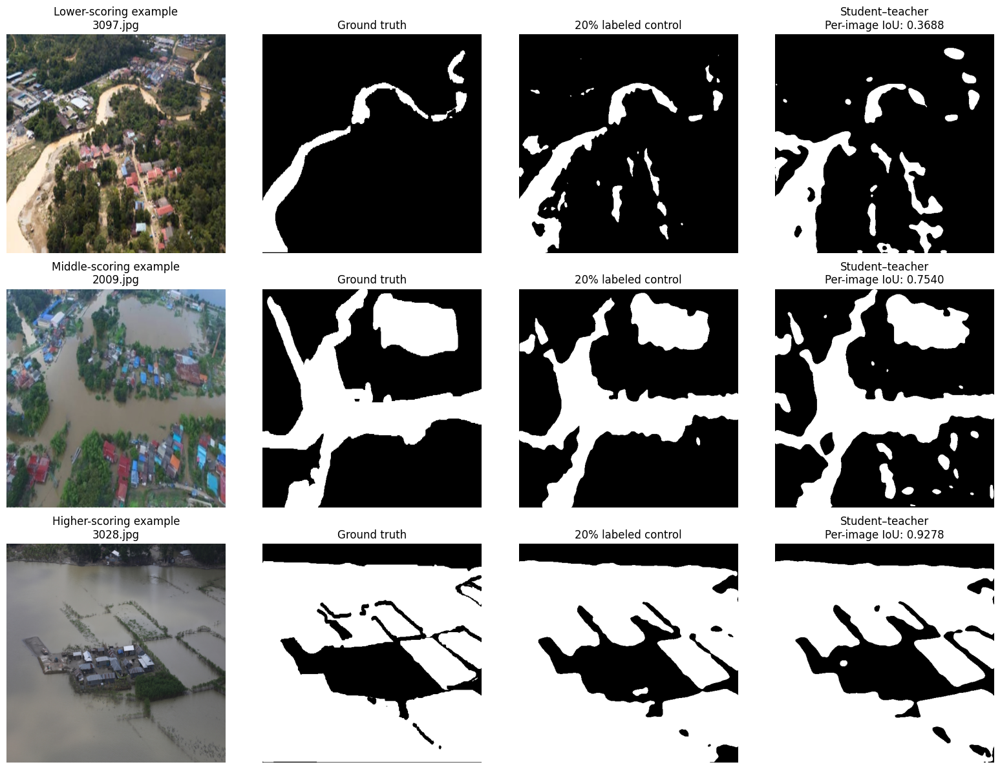

Saved figure: /content/drive/MyDrive/DLP_Project/resnet50_fedavg_student_teacher_20pct/control_vs_student_teacher_examples.png
Saved per-image scores: /content/drive/MyDrive/DLP_Project/resnet50_fedavg_student_teacher_20pct/student_teacher_test_per_image_iou.csv


In [28]:
import matplotlib.pyplot as plt


control_checkpoint = torch.load(
    CONTROL_BEST_PATH,
    map_location="cpu",
    weights_only=False,
)

ssl_checkpoint = torch.load(
    SSL_BEST_PATH,
    map_location="cpu",
    weights_only=False,
)

control_model = copy.deepcopy(ssl_global_model)
control_model.load_state_dict(control_checkpoint["model_state"])
control_model.to(device)
control_model.eval()

student_teacher_model = copy.deepcopy(ssl_global_model)
student_teacher_model.load_state_dict(ssl_checkpoint["model_state"])
student_teacher_model.to(device)
student_teacher_model.eval()


per_image_results = []

with torch.inference_mode():
    for index in range(len(test_dataset)):
        image, mask = test_dataset[index]

        logits = student_teacher_model(
            image.unsqueeze(0).to(device)
        )

        prediction = logits[0, 0].cpu() > 0
        target = mask[0] > 0.5

        intersection = (prediction & target).sum().item()
        union = (prediction | target).sum().item()

        
        image_iou = intersection / union if union else 1.0

        per_image_results.append({
            "index": index,
            "image": test_df.iloc[index]["Image"],
            "student_teacher_iou": image_iou,
        })

per_image_df = pd.DataFrame(per_image_results).sort_values(
    "student_teacher_iou"
).reset_index(drop=True)

selected_rows = [
    ("Lower-scoring example", per_image_df.iloc[0]),
    ("Middle-scoring example", per_image_df.iloc[len(per_image_df) // 2]),
    ("Higher-scoring example", per_image_df.iloc[-1]),
]

fig, axes = plt.subplots(
    len(selected_rows), 4,
    figsize=(16, 12),
)

with torch.inference_mode():
    for row_number, (label, row) in enumerate(selected_rows):
        index = int(row["index"])
        image, mask = test_dataset[index]
        input_image = image.unsqueeze(0).to(device)

        control_prediction = (
            control_model(input_image)[0, 0].cpu() > 0
        )

        ssl_prediction = (
            student_teacher_model(input_image)[0, 0].cpu() > 0
        )

        display_image = (
            image * IMAGENET_STD + IMAGENET_MEAN
        ).clamp(0, 1)

        axes[row_number, 0].imshow(
            display_image.permute(1, 2, 0).numpy()
        )
        axes[row_number, 0].set_title(
            f"{label}\n{row['image']}"
        )

        axes[row_number, 1].imshow(mask[0], cmap="gray", vmin=0, vmax=1)
        axes[row_number, 1].set_title("Ground truth")

        axes[row_number, 2].imshow(
            control_prediction, cmap="gray", vmin=0, vmax=1
        )
        axes[row_number, 2].set_title("20% labeled control")

        axes[row_number, 3].imshow(
            ssl_prediction, cmap="gray", vmin=0, vmax=1
        )
        axes[row_number, 3].set_title(
            f"Student–teacher\n"
            f"Per-image IoU: {row['student_teacher_iou']:.4f}"
        )

        for axis in axes[row_number]:
            axis.axis("off")

plt.tight_layout()

figure_path = SSL_OUTPUT_DIR / "control_vs_student_teacher_examples.png"
plt.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

per_image_path = SSL_OUTPUT_DIR / "student_teacher_test_per_image_iou.csv"
per_image_df.to_csv(per_image_path, index=False)

print("Saved figure:", figure_path)
print("Saved per-image scores:", per_image_path)

## FedProx and student-teacher training

In [29]:
import copy
import os
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F






FEDPROX_MU = 0.01
FEDPROX_ROUNDS = 60

FEDPROX_OUTPUT_DIR = (
    PROJECT_DIR / "resnet50_fedprox_student_teacher_20pct"
)
FEDPROX_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FEDPROX_LAST_PATH = FEDPROX_OUTPUT_DIR / "last_checkpoint.pt"
FEDPROX_BEST_PATH = FEDPROX_OUTPUT_DIR / "best_checkpoint.pt"
FEDPROX_HISTORY_PATH = FEDPROX_OUTPUT_DIR / "training_history.csv"

assert torch.cuda.is_available(), "Connect to a GPU runtime first."
device = torch.device("cuda")

ssl_global_model = ssl_global_model.to(device)


def train_fedprox_ssl_client(global_state, client_id, round_number):
    student = copy.deepcopy(ssl_global_model)
    student.load_state_dict(global_state)
    student.train()

    teacher = copy.deepcopy(student)
    teacher.requires_grad_(False)
    teacher.eval()

    optimizer = torch.optim.Adam(
        student.parameters(),
        lr=SSL_LR,
        betas=(0.9, 0.999),
    )

    
    
    global_parameters = {
        name: parameter.detach().clone()
        for name, parameter in student.named_parameters()
        if parameter.requires_grad
    }

    weight_u = unsupervised_weight(round_number)

    labeled_loader = ssl_labeled_loaders[client_id]
    labeled_iterator = iter(labeled_loader)

    unlabeled_loader = ssl_unlabeled_loaders[client_id]
    unlabeled_iterator = (
        iter(unlabeled_loader) if weight_u > 0 else None
    )

    supervised_sum = 0.0
    proximal_sum = 0.0
    labeled_presentations = 0

    unsupervised_sum = 0.0
    unlabeled_pixels = 0
    unlabeled_presentations = 0
    accepted_pixels = 0
    accepted_flood_pixels = 0

    steps = ssl_steps_per_round[client_id]

    for step in range(steps):
        try:
            labeled_images, labeled_masks = next(labeled_iterator)
        except StopIteration:
            labeled_iterator = iter(labeled_loader)
            labeled_images, labeled_masks = next(labeled_iterator)

        labeled_images = labeled_images.to(device)
        labeled_masks = labeled_masks.to(device)

        optimizer.zero_grad(set_to_none=True)

        labeled_logits = student(labeled_images)
        supervised_loss = F.binary_cross_entropy_with_logits(
            labeled_logits, labeled_masks
        )

        if not torch.isfinite(supervised_loss).item():
            raise RuntimeError(
                f"Non-finite supervised loss: client {client_id}"
            )

        
        proximal_squared = torch.zeros((), device=device)

        for name, parameter in student.named_parameters():
            if parameter.requires_grad:
                proximal_squared = proximal_squared + (
                    parameter - global_parameters[name]
                ).square().sum()

        proximal_loss = (FEDPROX_MU / 2.0) * proximal_squared

        if not torch.isfinite(proximal_loss).item():
            raise RuntimeError(
                f"Non-finite proximal loss: client {client_id}"
            )

        (supervised_loss + proximal_loss).backward()

        batch_count = labeled_images.shape[0]
        supervised_sum += supervised_loss.item() * batch_count
        proximal_sum += proximal_loss.item() * batch_count
        labeled_presentations += batch_count

        if weight_u > 0:
            try:
                weak_images, strong_images = next(unlabeled_iterator)
            except StopIteration:
                unlabeled_iterator = iter(unlabeled_loader)
                weak_images, strong_images = next(unlabeled_iterator)

            weak_images = weak_images.to(device)
            strong_images = strong_images.to(device)

            with torch.no_grad():
                teacher_logits = teacher(weak_images)

            
            batchnorm_layers = [
                layer for layer in student.modules()
                if isinstance(layer, nn.modules.batchnorm._BatchNorm)
            ]

            for layer in batchnorm_layers:
                layer.eval()

            try:
                strong_logits = student(strong_images)

                unsupervised_loss, accepted, pseudo_labels = (
                    confidence_filtered_loss(
                        strong_logits,
                        teacher_logits,
                    )
                )

                if not torch.isfinite(unsupervised_loss).item():
                    raise RuntimeError(
                        f"Non-finite SSL loss: client {client_id}"
                    )

                (weight_u * unsupervised_loss).backward()

            finally:
                for layer in batchnorm_layers:
                    layer.train()

            pixel_count = accepted.numel()

            unsupervised_sum += (
                unsupervised_loss.item() * pixel_count
            )
            unlabeled_pixels += pixel_count
            unlabeled_presentations += weak_images.shape[0]
            accepted_pixels += accepted.sum().item()
            accepted_flood_pixels += (
                accepted & (pseudo_labels > 0.5)
            ).sum().item()

        for parameter in student.parameters():
            if parameter.grad is not None:
                if not torch.isfinite(parameter.grad).all().item():
                    raise RuntimeError(
                        f"Non-finite gradients: client {client_id}"
                    )

        optimizer.step()
        update_ema_teacher(teacher, student, step + 1)

    updated_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in student.state_dict().items()
    }

    metrics = {
        "supervised_loss": supervised_sum / labeled_presentations,
        "proximal_loss": proximal_sum / labeled_presentations,
        "unsupervised_loss": (
            unsupervised_sum / unlabeled_pixels
            if unlabeled_pixels else 0.0
        ),
        "unsupervised_weight": weight_u,
        "pseudo_label_coverage": (
            accepted_pixels / unlabeled_pixels
            if unlabeled_pixels else 0.0
        ),
        "accepted_flood_fraction": (
            accepted_flood_pixels / accepted_pixels
            if accepted_pixels else 0.0
        ),
        "labeled_presentations": labeled_presentations,
        "unlabeled_presentations": unlabeled_presentations,
        "steps": steps,
    }

    del student, teacher, optimizer, global_parameters

    return updated_state, metrics


def save_fedprox_checkpoint(path, state):
    temporary_path = path.with_suffix(".tmp")
    torch.save(state, temporary_path)
    os.replace(temporary_path, path)



fedprox_config = {
    "experiment": "fedprox_student_teacher_20pct",
    "mu": FEDPROX_MU,
    "seed": SEED,
    "rounds": FEDPROX_ROUNDS,
    "learning_rate": SSL_LR,
    "batch_size": BATCH_SIZE,
    "confidence": SSL_CONFIDENCE,
    "ema_decay": SSL_EMA_DECAY,
    "warmup_rounds": SSL_WARMUP_ROUNDS,
    "ramp_rounds": SSL_RAMP_ROUNDS,
    "max_unsupervised_weight": SSL_MAX_WEIGHT,
    "steps_per_client": ssl_steps_per_round.copy(),
    "client_weights": ssl_weights.copy(),
    "device": "cuda",
    "precision": "float32",
}






if FEDPROX_LAST_PATH.exists():
    checkpoint = torch.load(
        FEDPROX_LAST_PATH,
        map_location="cpu",
        weights_only=False,
    )

    assert checkpoint["config"] == fedprox_config, (
        "FedProx checkpoint settings do not match. "
        "Share this error before continuing."
    )

    ssl_global_model.load_state_dict(checkpoint["model_state"])

    completed_round = checkpoint["round"]
    best_val_iou = checkpoint["best_val_iou"]
    best_round = checkpoint["best_round"]
    fedprox_history = list(checkpoint["history"])

    random.setstate(checkpoint["python_rng"])
    np.random.set_state(checkpoint["numpy_rng"])
    torch.set_rng_state(checkpoint["torch_rng"])
    torch.cuda.set_rng_state(checkpoint["cuda_rng"])

    for client_id in (1, 2, 3):
        ssl_labeled_generators[client_id].set_state(
            checkpoint["labeled_generator_states"][client_id]
        )
        ssl_unlabeled_generators[client_id].set_state(
            checkpoint["unlabeled_generator_states"][client_id]
        )

    print(f"Resuming after round {completed_round}.")

else:
    assert not FEDPROX_BEST_PATH.exists(), (
        "A best checkpoint exists without a last checkpoint. "
        "Share this message before continuing."
    )

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    for client_id in (1, 2, 3):
        ssl_labeled_generators[client_id].manual_seed(
            SEED + client_id
        )
        ssl_unlabeled_generators[client_id].manual_seed(
            SEED + 1000 + client_id
        )

    ssl_global_model.load_state_dict(fed_initial_state)

    completed_round = 0
    best_val_iou = -1.0
    best_round = 0
    fedprox_history = []

    print("Starting FedProx + student–teacher from round 1.")






for round_number in range(completed_round + 1, FEDPROX_ROUNDS + 1):
    round_start = time.time()

    round_start_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in ssl_global_model.state_dict().items()
    }

    client_states = {}
    client_metrics = {}

    print(
        f"\nRound {round_number}/{FEDPROX_ROUNDS} | "
        f"Unsupervised weight: {unsupervised_weight(round_number):.2f}",
        flush=True,
    )

    for client_id in (1, 2, 3):
        client_start = time.time()

        state, metrics = train_fedprox_ssl_client(
            round_start_state,
            client_id,
            round_number,
        )

        client_states[client_id] = state
        client_metrics[client_id] = metrics

        print(
            f"Client {client_id} | "
            f"Supervised: {metrics['supervised_loss']:.4f} | "
            f"Proximal: {metrics['proximal_loss']:.6f} | "
            f"Unsupervised: {metrics['unsupervised_loss']:.4f} | "
            f"Coverage: {metrics['pseudo_label_coverage']:.2%} | "
            f"{time.time() - client_start:.1f}s",
            flush=True,
        )

    aggregated_state = aggregate_ssl_states(
        client_states,
        ssl_weights,
    )

    ssl_global_model.load_state_dict(aggregated_state)
    val_metrics = evaluate_ssl_cpu(ssl_global_model, val_loader)

    improved = val_metrics["iou"] > best_val_iou

    if improved:
        best_val_iou = val_metrics["iou"]
        best_round = round_number

    row = {
        "round": round_number,
        "unsupervised_weight": unsupervised_weight(round_number),
        "weighted_supervised_loss": sum(
            ssl_weights[k] * client_metrics[k]["supervised_loss"]
            for k in ssl_weights
        ),
        "weighted_proximal_loss": sum(
            ssl_weights[k] * client_metrics[k]["proximal_loss"]
            for k in ssl_weights
        ),
        "weighted_unsupervised_loss": sum(
            ssl_weights[k] * client_metrics[k]["unsupervised_loss"]
            for k in ssl_weights
        ),
        "weighted_pseudo_label_coverage": sum(
            ssl_weights[k] * client_metrics[k]["pseudo_label_coverage"]
            for k in ssl_weights
        ),
        **{
            f"client_{client_id}_{name}": value
            for client_id, metrics in client_metrics.items()
            for name, value in metrics.items()
        },
        **{
            f"val_{name}": value
            for name, value in val_metrics.items()
        },
        "seconds": time.time() - round_start,
    }

    fedprox_history.append(row)

    checkpoint = {
        "config": fedprox_config,
        "round": round_number,
        "model_state": aggregated_state,
        "best_val_iou": best_val_iou,
        "best_round": best_round,
        "history": fedprox_history.copy(),
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state(),
        "labeled_generator_states": {
            k: generator.get_state()
            for k, generator in ssl_labeled_generators.items()
        },
        "unlabeled_generator_states": {
            k: generator.get_state()
            for k, generator in ssl_unlabeled_generators.items()
        },
    }

    if improved:
        save_fedprox_checkpoint(FEDPROX_BEST_PATH, checkpoint)

    save_fedprox_checkpoint(FEDPROX_LAST_PATH, checkpoint)

    pd.DataFrame(fedprox_history).to_csv(
        FEDPROX_HISTORY_PATH,
        index=False,
    )

    print(
        f"Val IoU: {val_metrics['iou']:.6f} | "
        f"Val F1: {val_metrics['f1']:.6f} | "
        f"Best IoU: {best_val_iou:.6f} "
        f"at round {best_round} | "
        f"Time: {time.time() - round_start:.1f}s",
        flush=True,
    )
    print("Checkpoint saved.", flush=True)


print("\nFedProx + student–teacher training complete.")
print(f"Best validation IoU: {best_val_iou:.6f}")
print(f"Best round: {best_round}")
print("Results directory:", FEDPROX_OUTPUT_DIR)
print("Test set: not evaluated.")

Starting FedProx + student–teacher from round 1.

Round 1/60 | Unsupervised weight: 0.00
Client 1 | Supervised: 0.5349 | Proximal: 0.923008 | Unsupervised: 0.0000 | Coverage: 0.00% | 27.7s
Client 2 | Supervised: 0.5932 | Proximal: 0.595741 | Unsupervised: 0.0000 | Coverage: 0.00% | 9.0s
Client 3 | Supervised: 0.5751 | Proximal: 0.639745 | Unsupervised: 0.0000 | Coverage: 0.00% | 10.9s
Val IoU: 0.694414 | Val F1: 0.819651 | Best IoU: 0.694414 at round 1 | Time: 51.8s
Checkpoint saved.

Round 2/60 | Unsupervised weight: 0.00
Client 1 | Supervised: 0.4869 | Proximal: 0.376056 | Unsupervised: 0.0000 | Coverage: 0.00% | 25.6s
Client 2 | Supervised: 0.5109 | Proximal: 0.332234 | Unsupervised: 0.0000 | Coverage: 0.00% | 9.1s
Client 3 | Supervised: 0.4571 | Proximal: 0.312650 | Unsupervised: 0.0000 | Coverage: 0.00% | 11.2s
Val IoU: 0.672890 | Val F1: 0.804464 | Best IoU: 0.694414 at round 1 | Time: 49.0s
Checkpoint saved.

Round 3/60 | Unsupervised weight: 0.00
Client 1 | Supervised: 0.4486 |

## FedProx test evaluation

In [2]:
from google.colab import drive
from pathlib import Path
import zipfile
import json

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet50






drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/DLP_Project")
ZIP_PATH = PROJECT_DIR / "flood_area.zip"
DATA_RECORD_DIR = PROJECT_DIR / "dataset_records"

FEDPROX_OUTPUT_DIR = (
    PROJECT_DIR / "resnet50_fedprox_student_teacher_20pct"
)
FEDPROX_BEST_PATH = FEDPROX_OUTPUT_DIR / "best_checkpoint.pt"

assert ZIP_PATH.is_file(), f"Dataset ZIP missing: {ZIP_PATH}"
assert FEDPROX_BEST_PATH.is_file(), (
    f"FedProx checkpoint missing: {FEDPROX_BEST_PATH}"
)

device = torch.device("cpu")
IMAGE_SIZE = (512, 512)
BATCH_SIZE = 8

val_df = pd.read_csv(DATA_RECORD_DIR / "val_seed42.csv")
test_df = pd.read_csv(DATA_RECORD_DIR / "test_seed42.csv")

extract_dir = Path("/content/dlp_flood_data")

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    metadata_paths = [
        name for name in archive.namelist()
        if Path(name).name.lower() == "metadata.csv"
        and "__MACOSX" not in name
    ]

    assert len(metadata_paths) == 1, (
        f"Expected one metadata.csv, found: {metadata_paths}"
    )

    archive.extractall(extract_dir)

DATA_ROOT = (extract_dir / metadata_paths[0]).parent






IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406], dtype=torch.float32
).view(3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225], dtype=torch.float32
).view(3, 1, 1)


class FloodDataset(Dataset):
    def __init__(self, dataframe, data_root):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.data_root = Path(data_root)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(self.data_root / "Image" / row["Image"]) as image:
            image = image.convert("RGB").resize(
                IMAGE_SIZE, Image.Resampling.BILINEAR
            )
            image = np.array(image, dtype=np.float32) / 255.0

        with Image.open(self.data_root / "Mask" / row["Mask"]) as mask:
            mask = mask.convert("L").resize(
                IMAGE_SIZE, Image.Resampling.NEAREST
            )
            mask = (np.array(mask) > 0).astype(np.float32)

        image = torch.from_numpy(image).permute(2, 0, 1).contiguous()
        image = (image - IMAGENET_MEAN) / IMAGENET_STD
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


val_loader = DataLoader(
    FloodDataset(val_df, DATA_ROOT),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    FloodDataset(test_df, DATA_ROOT),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)






class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.conv = DoubleConv(in_channels + skip_channels, out_channels)

    def forward(self, x, skip):
        x = F.interpolate(
            x,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )
        return self.conv(torch.cat([x, skip], dim=1))


class ResNet50UNet(nn.Module):
    def __init__(self):
        super().__init__()

        
        encoder = resnet50(weights=None)

        self.stem = nn.Sequential(
            encoder.conv1, encoder.bn1, encoder.relu
        )
        self.pool = encoder.maxpool
        self.encoder1 = encoder.layer1
        self.encoder2 = encoder.layer2
        self.encoder3 = encoder.layer3
        self.encoder4 = encoder.layer4

        self.decoder4 = DecoderBlock(2048, 1024, 256)
        self.decoder3 = DecoderBlock(256, 512, 128)
        self.decoder2 = DecoderBlock(128, 256, 64)
        self.decoder1 = DecoderBlock(64, 64, 32)

        self.final_decoder = DoubleConv(32, 16)
        self.head = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        input_size = x.shape[-2:]

        s0 = self.stem(x)
        s1 = self.encoder1(self.pool(s0))
        s2 = self.encoder2(s1)
        s3 = self.encoder3(s2)
        bottleneck = self.encoder4(s3)

        x = self.decoder4(bottleneck, s3)
        x = self.decoder3(x, s2)
        x = self.decoder2(x, s1)
        x = self.decoder1(x, s0)

        x = F.interpolate(
            x,
            size=input_size,
            mode="bilinear",
            align_corners=False,
        )

        return self.head(self.final_decoder(x))






def evaluate_model(network, loader):
    network.eval()

    total_loss = 0.0
    samples_seen = 0
    counts = torch.zeros(4, dtype=torch.int64)

    with torch.inference_mode():
        for batch_images, batch_masks in loader:
            batch_images = batch_images.to(device)
            batch_masks = batch_masks.to(device)

            logits = network(batch_images)
            loss = F.binary_cross_entropy_with_logits(
                logits, batch_masks
            )

            assert torch.isfinite(logits).all()
            assert torch.isfinite(loss).item()

            batch_count = batch_images.shape[0]
            total_loss += loss.item() * batch_count
            samples_seen += batch_count

            predicted = logits > 0
            target = batch_masks > 0.5

            counts += torch.stack([
                (predicted & target).sum(),
                (predicted & ~target).sum(),
                (~predicted & target).sum(),
                (~predicted & ~target).sum(),
            ]).cpu()

    tp, fp, fn, tn = counts.tolist()

    return {
        "loss": total_loss / samples_seen,
        "iou": tp / max(tp + fp + fn, 1),
        "precision": tp / max(tp + fp, 1),
        "recall": tp / max(tp + fn, 1),
        "f1": 2 * tp / max(2 * tp + fp + fn, 1),
        "pixel_accuracy": (tp + tn) / max(tp + fp + fn + tn, 1),
    }






fedprox_checkpoint = torch.load(
    FEDPROX_BEST_PATH,
    map_location="cpu",
    weights_only=False,
)

model = ResNet50UNet().to(device)
model.load_state_dict(fedprox_checkpoint["model_state"])
model.eval()

selected_round = fedprox_checkpoint["round"]
saved_val_iou = fedprox_checkpoint["best_val_iou"]

print("Device:", device)
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Selected round:", selected_round)
print(f"Saved validation IoU: {saved_val_iou:.6f}")

print("\nEvaluating validation set on CPU...", flush=True)
fedprox_val_metrics = evaluate_model(model, val_loader)

recomputed_val_iou = fedprox_val_metrics["iou"]
difference = abs(recomputed_val_iou - saved_val_iou)

print(f"Recomputed validation IoU: {recomputed_val_iou:.6f}")
print(f"Absolute difference: {difference:.8f}")

assert difference < 1e-3, (
    "The recomputed validation IoU differs from the saved result. "
    "Share this output before evaluating the test set."
)






print("\nEvaluating held-out test set on CPU...", flush=True)
fedprox_test_metrics = evaluate_model(model, test_loader)

print("\nFedProx + student–teacher test results:")
for name, value in fedprox_test_metrics.items():
    print(f"{name}: {value:.6f}")

result = {
    "experiment": "fedprox_student_teacher_20pct",
    "selected_round": selected_round,
    "mu": fedprox_checkpoint["config"]["mu"],
    "evaluation_device": "cpu",
    "saved_validation_iou": saved_val_iou,
    "validation_metrics": fedprox_val_metrics,
    "test_metrics": fedprox_test_metrics,
}

result_path = FEDPROX_OUTPUT_DIR / "best_model_test_results.json"

with open(result_path, "w") as file:
    json.dump(result, file, indent=2)

print("\nSaved results:", result_path)

Mounted at /content/drive
Device: cpu
Validation images: 29
Test images: 44
Selected round: 10
Saved validation IoU: 0.725984

Evaluating validation set on CPU...
Recomputed validation IoU: 0.725985
Absolute difference: 0.00000036

Evaluating held-out test set on CPU...

FedProx + student–teacher test results:
loss: 0.332647
iou: 0.760129
precision: 0.803377
recall: 0.933863
f1: 0.863720
pixel_accuracy: 0.868232

Saved results: /content/drive/MyDrive/DLP_Project/resnet50_fedprox_student_teacher_20pct/best_model_test_results.json


## Validation comparison

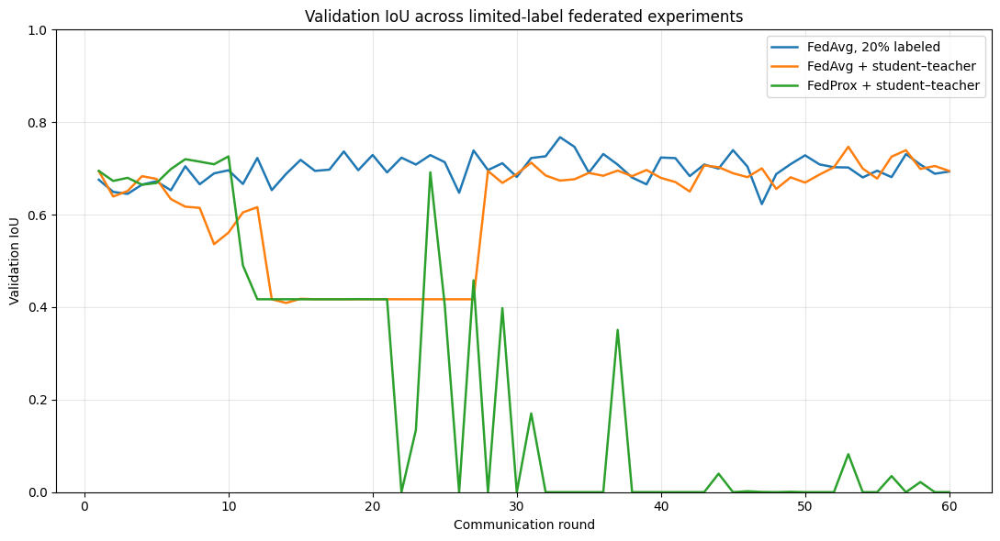

Saved figure: /content/drive/MyDrive/DLP_Project/resnet50_fedprox_student_teacher_20pct/limited_label_validation_iou_comparison.png


In [3]:
from pathlib import Path
import pandas as pd
import torch
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/drive/MyDrive/DLP_Project")

control_path = (
    PROJECT_DIR
    / "resnet50_fedavg_labeled20_control"
    / "training_history.csv"
)

ssl_checkpoint_path = (
    PROJECT_DIR
    / "resnet50_fedavg_student_teacher_20pct"
    / "last_checkpoint.pt"
)

fedprox_path = (
    PROJECT_DIR
    / "resnet50_fedprox_student_teacher_20pct"
    / "training_history.csv"
)

for path in [control_path, ssl_checkpoint_path, fedprox_path]:
    assert path.is_file(), f"File not found: {path}"

control_history = pd.read_csv(control_path)

ssl_checkpoint = torch.load(
    ssl_checkpoint_path,
    map_location="cpu",
    weights_only=False,
)
ssl_history = pd.DataFrame(ssl_checkpoint["history"])

fedprox_history = pd.read_csv(fedprox_path)

histories = [
    ("FedAvg, 20% labeled", control_history),
    ("FedAvg + student–teacher", ssl_history),
    ("FedProx + student–teacher", fedprox_history),
]

fig, ax = plt.subplots(figsize=(11, 6))

for label, history in histories:
    assert {"round", "val_iou"}.issubset(history.columns), (
        f"Missing round or val_iou column for {label}"
    )

    history = history.sort_values("round")

    ax.plot(
        history["round"],
        history["val_iou"],
        label=label,
        linewidth=1.8,
    )

ax.set_title("Validation IoU across limited-label federated experiments")
ax.set_xlabel("Communication round")
ax.set_ylabel("Validation IoU")
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

figure_path = (
    PROJECT_DIR
    / "resnet50_fedprox_student_teacher_20pct"
    / "limited_label_validation_iou_comparison.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", figure_path)